In [1]:
print('h')

h


In [2]:
%pip install evaluate
%pip install contractions

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 2.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 345.1/345.1 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 8.3 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.


In [3]:
!rm -rf /kaggle/working/*

# Dataset Loading and Train-Test-Validation Splitting

## Loading

In [4]:
from datasets import load_dataset, load_from_disk, Dataset, DatasetDict

aug_file_path = "/kaggle/input/datasets/shadmanshafeen141/bpd-qna-classification-dataset-augmented/augmented_dataset"
# file_path = "/kaggle/input/datasets/shadmanshafeen141/bpd-question-and-answer-classification-dataset/BPDQAC Dataset.csv"  # Baseline raw dataset disabled
# dataset = load_dataset("csv" , data_files=file_path)  # Disabled: baseline path not used
augmented_dataset = load_from_disk(aug_file_path)

# Keep a compatibility variable for downstream exploratory cells
dataset = augmented_dataset["train"]

print("Augmented Dataset:", augmented_dataset)
print("Working Dataset (train split):", dataset)

Augmented Dataset: DatasetDict({
    train: Dataset({
        features: ['id', 'participant_id', 'question_id', 'question', 'answer', 'label', 'Criteria B', 'Criteria C', 'Criteria D', 'Criteria E', 'Criteria F'],
        num_rows: 5238
    })
    test: Dataset({
        features: ['id', 'participant_id', 'question_id', 'question', 'answer', 'label', 'Criteria B', 'Criteria C', 'Criteria D', 'Criteria E', 'Criteria F'],
        num_rows: 333
    })
    validation: Dataset({
        features: ['id', 'participant_id', 'question_id', 'question', 'answer', 'label', 'Criteria B', 'Criteria C', 'Criteria D', 'Criteria E', 'Criteria F'],
        num_rows: 333
    })
})
Working Dataset (train split): Dataset({
    features: ['id', 'participant_id', 'question_id', 'question', 'answer', 'label', 'Criteria B', 'Criteria C', 'Criteria D', 'Criteria E', 'Criteria F'],
    num_rows: 5238
})


## Solving Contractions

In [5]:
import pandas as pd
import numpy as np
import re
import contractions  # Make sure to install: pip install contractions

class TextNormalizer:
    def __init__(self):
        # Initialize text normalization dictionary
        self.slang_dict = {
            'imo': 'in my opinion',
            'imho': 'in my humble opinion',
            'tbh': 'to be honest',
            'afaik': 'as far as i know',
            'idk': "i don't know",
            'smh': 'shaking my head',
            'btw': 'by the way',
            'asap': 'as soon as possible',
            'fyi': 'for your information',
            'np': 'no problem',
            'thx': 'thanks',
            'pls': 'please',
            'u': 'you',
            'r': 'are',
            'ur': 'your',
            'n': 'and',
            'b/c': 'because',
            'cz' : 'because',
            'bcz' : 'because',
            'ofc' : 'ofcourse',
            'govt': 'government',
            'dept': 'department',
            'est': 'established',
            'approx': 'approximately',
            'min': 'minimum',
            'max': 'maximum',
            "n't": 'not',
            "nt" : 'not',
            "gn" : 'good night',
            "f9" : 'fine',
            'bpd': 'borderline personality disorder',
            'dbt': 'dialectical behavior therapy',
            'fp': 'favorite person',
            'si': 'suicidal ideation',
            'sh': 'self harm',
            "its" : 'it is',
            "people's" : 'people',
            "sha'n't": "shall not",
            "shan't've": "shall not have",
            "she'd": "she had / she would",
            "she'd've": "she would have",
            "she'll": "she shall / she will",
            "she'll've": "she shall have / she will have",
            "she's": "she has / she is",
            "should've": "should have",
            "shouldn't": "should not",
            "shouldn't've": "should not have",
            "so've": "so have",
            "so's": "so as / so is",
            "that'd": "that would / that had",
            "that'd've": "that would have",
            "that's": "that has / that is",
            "there'd": "there had / there would",
            "there'd've": "there would have",
            "there's": "there has / there is",
            "they'd": "they had / they would",
            "they'd've": "they would have",
            "they'll": "they shall / they will",
            "they'll've": "they shall have / they will have",
            "they're": "they are",
            "they've": "they have",
            "to've": "to have",
            "wasn't": "was not",
            "we'd": "we had / we would",
            "we'd've": "we would have",
            "we'll": "we will",
            "we'll've": "we will have",
            "we're": "we are",
            "we've": "we have",
            "weren't": "were not",
            "what'll": "what shall / what will",
            "what'll've": "what shall have / what will have",
            "what're": "what are",
            "what's": "what has / what is",
            "what've": "what have",
            "when's": "when has / when is",
            "when've": "when have",
            "where'd": "where did",
            "where's": "where has / where is",
            "where've": "where have",
            "who'll": "who shall / who will",
            "who'll've": "who shall have / who will have",
            "who's": "who has / who is",
            "who've": "who have",
            "why's": "why has / why is",
            "why've": "why have",
            "will've": "will have",
            "won't": "will not",
            "won't've": "will not have",
            "would've": "would have",
            "wouldn't": "would not",
            "wouldn't've": "would not have",
            "y'all": "you all",
            "y'all'd": "you all would",
            "y'all'd've": "you all would have",
            "y'all're": "you all are",
            "y'all've": "you all have",
            "you'd": "you had / you would",
            "you'd've": "you would have",
            "you'll": "you shall / you will",
            "you'll've": "you shall have / you will have",
            "you're": "you are",
            "you've": "you have"
}

    def clean_text(self, text):
        """Basic text cleaning"""
        text = str(text).lower().strip()
        # Remove special characters (keep basic punctuation)
        text = re.sub(r"[^a-zA-Z0-9\s.,!?']", "", text)
        return text

    def expand_slang(self, text):
        """Replace slang terms using dictionary"""
        words = text.split()
        expanded_words = [self.slang_dict.get(word, word) for word in words]
        return ' '.join(expanded_words)

    def normalize_text(self, text):
        """Full text normalization pipeline"""
        if not isinstance(text, str) or not text.strip():
            return text
            
        # Clean text first
        text = self.clean_text(text)
        # Fix contractions
        text = contractions.fix(text)
        # Expand slang
        text = self.expand_slang(text)
        return text

# Convert to pandas DataFrame for easier processing
df = dataset.to_pandas()
aug_df_train = augmented_dataset['train'].to_pandas()
aug_df_test = augmented_dataset['test'].to_pandas()
aug_df_validation = augmented_dataset['validation'].to_pandas()

# Initialize normalizer
normalizer = TextNormalizer()

# Apply normalization to text columns
text_columns = ['question', 'answer']
for col in text_columns:
    df[col] = df[col].apply(normalizer.normalize_text)
    aug_df_train[col] = aug_df_train[col].apply(normalizer.normalize_text)
    aug_df_test[col] = aug_df_test[col].apply(normalizer.normalize_text)
    aug_df_validation[col] = aug_df_validation[col].apply(normalizer.normalize_text)
    
clean_dataset = Dataset.from_pandas(df, preserve_index=False)

aug_clean_dataset_train = Dataset.from_pandas(aug_df_train, preserve_index=False)
aug_clean_dataset_test = Dataset.from_pandas(aug_df_test, preserve_index=False)
aug_clean_dataset_validation =  Dataset.from_pandas(aug_df_validation, preserve_index=False)
aug_clean_dataset = DatasetDict({
    "train":aug_clean_dataset_train,
    "test":aug_clean_dataset_test,
    "validation":aug_clean_dataset_validation
})
dataset = clean_dataset
augmented_dataset = aug_clean_dataset

## Question-Wise Stratified Splitting

In [6]:
# Baseline question-wise stratified split is disabled for augmented-only workflow.
# from collections import Counter
# from datasets import concatenate_datasets, DatasetDict
# qid_split_ds = {}
# ds = dataset.class_encode_column("label")
# for qid in range(1, 10):
#     split_ds = ds.filter(lambda row, q=qid: row["question_id"] == q)
#     qid_split_ds[qid] = split_ds
# question_split_dataset = {}
# train_splits = dataset.select([])
# test_splits = dataset.select([])
# validation_splits = dataset.select([])
# for i in range(1,10):
#     split1 = qid_split_ds[i].train_test_split(test_size=0.1 , seed=42, stratify_by_column="label")
#     split2 = split1["train"].train_test_split(test_size=0.1111 , seed=42, stratify_by_column="label")
#     train_splits = concatenate_datasets([split2['train'] , train_splits])
#     test_splits = concatenate_datasets([split2['test'] , test_splits])
#     validation_splits = concatenate_datasets([split1['test'] , validation_splits])
# question_split_dataset = DatasetDict({
#     'train' : train_splits,
#     'test' : test_splits,
#     'validation' : validation_splits
# })
# print(f"\nTrain set: {question_split_dataset['train'].num_rows} rows")
# print(f"Class Distribution: {Counter(question_split_dataset['train']['label'])}")
# print(f"\nTest set: {question_split_dataset['test'].num_rows} rows")
# print(f"Class Distribution: {Counter(question_split_dataset['test']['label'])}")
# print(f"\nValidation set: {question_split_dataset['validation'].num_rows} rows")
# print(f"Class Distribution: {Counter(question_split_dataset['validation']['label'])}")
# print("\n",Counter(question_split_dataset['train']['question_id']))

# For augmented-only workflow, use augmented split directly.
question_split_dataset = augmented_dataset
print("Baseline split disabled. Using augmented dataset splits directly.")

Baseline split disabled. Using augmented dataset splits directly.


## Data Visualization

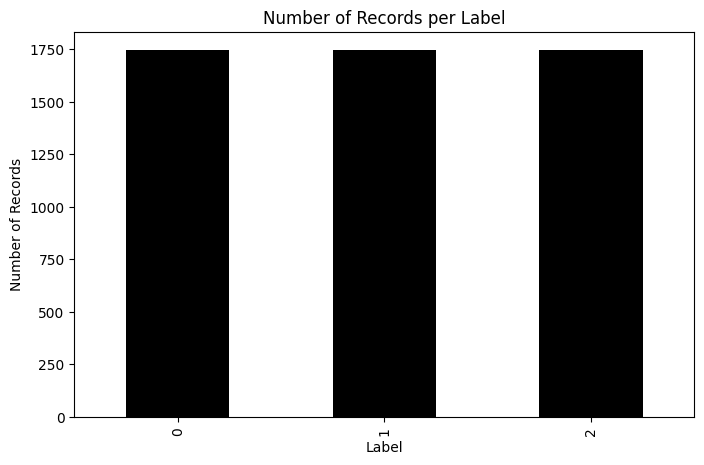

In [7]:
import matplotlib.pyplot as plt

df = dataset.to_pandas()

# Use pandas value_counts to count the labels
label_counts = df['label'].value_counts().sort_index()

label_counts.plot(kind='bar', figsize=(8, 5), color='black')
plt.xlabel('Label')
plt.ylabel('Number of Records')
plt.title('Number of Records per Label')
plt.show()

## Class Weights for Weighted Cross-Entropy Loss
###  Weight of Class i = sqrt (Total Number of Examples)/(Number of Classes x Examples in Class i)

In [8]:
# Weighted Cross-Entropy class weights are disabled per experiment scope.
# from sklearn.utils.class_weight import compute_class_weight
# import numpy as np
# import torch
# classes=np.unique(question_split_dataset['train']['label'])
# class_weights = compute_class_weight(class_weight='balanced', classes=np.unique(question_split_dataset['train']['label']), y=question_split_dataset['train']['label'])
# class_weights = torch.tensor(class_weights)
# class_weights = torch.sqrt(class_weights)
# class_weights = class_weights / class_weights.sum() * len(class_weights)
# class_weights = class_weights.to(device='cuda', dtype=torch.float32)
# print (f"Class Weights: {class_weights}")
print("Skipped: class-weight computation disabled (no weighted-loss runs).")

Skipped: class-weight computation disabled (no weighted-loss runs).


## Checking for Null Values

In [9]:
df = dataset.to_pandas()

# 2. Identify rows with at least one null
mask = df.isnull().any(axis=1)

# 3. Extract and print those rows
null_df = df[mask]
print(null_df)

Empty DataFrame
Columns: [id, participant_id, question_id, question, answer, label, Criteria B, Criteria C, Criteria D, Criteria E, Criteria F]
Index: []


# Tokenization

## Tokenization Function

In [10]:
# tokenizer also passed to ensure used tokenizer is of same checkpoint as the model
# Dynamic Padding. Hence, dp
def tokenize(example , tokenizer):
    return tokenizer(example["question"], example["answer"], truncation=True)

## Tokenization

In [11]:
from transformers import AutoTokenizer

### Electra

In [12]:
electra_checkpoint = 'google/electra-base-discriminator'
electra_tokenizer = AutoTokenizer.from_pretrained(electra_checkpoint)
# tokenized_dataset_dp_electra = question_split_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : electra_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_electra = augmented_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : electra_tokenizer})

config.json:   0%|          | 0.00/666 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/5238 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

### BERT

In [13]:
bert_checkpoint = "bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(bert_checkpoint)
# tokenized_dataset_dp_bert = question_split_dataset.map(tokenize , batched = True , fn_kwargs = {'tokenizer' : bert_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_bert = augmented_dataset.map(tokenize , batched = True , fn_kwargs = {'tokenizer' : bert_tokenizer})

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/5238 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

###  DistilBERT

In [14]:
distilbert_checkpoint = "distilbert/distilbert-base-uncased"
distilbert_tokenizer = AutoTokenizer.from_pretrained(distilbert_checkpoint)
# tokenized_dataset_dp_distilbert = question_split_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : distilbert_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_distilbert = augmented_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : distilbert_tokenizer})

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/5238 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

### RoBERTa

In [15]:
roberta_checkpoint = "FacebookAI/roberta-base"
roberta_tokenizer = AutoTokenizer.from_pretrained(roberta_checkpoint)
# tokenized_dataset_dp_roberta = question_split_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : roberta_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_roberta = augmented_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : roberta_tokenizer})

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/5238 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

### PsychBERT

In [16]:
# PsychBERT tokenization is disabled entirely per experiment scope.
# psychbert_checkpoint = "mnaylor/psychbert-cased"
# psychbert_tokenizer = AutoTokenizer.from_pretrained(psychbert_checkpoint)
# tokenized_dataset_dp_psychbert = question_split_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : psychbert_tokenizer})
# augmented_tokenized_dataset_dp_psychbert = augmented_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : psychbert_tokenizer})
print("Skipped: PsychBERT section disabled.")

Skipped: PsychBERT section disabled.


### XLNet

In [17]:
xlnet_checkpoint = "xlnet/xlnet-base-cased"
xlnet_tokenizer = AutoTokenizer.from_pretrained(xlnet_checkpoint)
# tokenized_dataset_dp_xlnet = question_split_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : xlnet_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_xlnet = augmented_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : xlnet_tokenizer})

config.json:   0%|          | 0.00/760 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/798k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/5238 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

### DeBERTa

In [18]:
deberta_checkpoint = "microsoft/deberta-v3-base"
deberta_tokenizer = AutoTokenizer.from_pretrained(deberta_checkpoint, use_fast=False)
# tokenized_dataset_dp_deberta = question_split_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : deberta_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_deberta = augmented_dataset.map(tokenize, batched=True , fn_kwargs= {'tokenizer' : deberta_tokenizer})


config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

Map:   0%|          | 0/5238 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

### ModernBERT


In [19]:
modernbert_checkpoint = "answerdotai/ModernBERT-base"
try:
    modernbert_tokenizer = AutoTokenizer.from_pretrained(modernbert_checkpoint)
except Exception as ex:
    raise RuntimeError(
        "ModernBERT could not be loaded in this environment. If your Transformers build is too old, upgrade it before running this cell."
    ) from ex
# tokenized_dataset_dp_modernbert = question_split_dataset.map(tokenize, batched=True, fn_kwargs={'tokenizer': modernbert_tokenizer})  # Raw baseline disabled
augmented_tokenized_dataset_dp_modernbert = augmented_dataset.map(tokenize, batched=True, fn_kwargs={'tokenizer': modernbert_tokenizer})


config.json: 0.00B [00:00, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

Map:   0%|          | 0/5238 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

### T5

In [20]:
t5_checkpoint = "google-t5/t5-small"

from transformers import T5Tokenizer
t5_tokenizer = T5Tokenizer.from_pretrained(t5_checkpoint)

def t5_preprocess(example):
    inputs = [
        f"trinary classification: {question} </s> {answer}"
        for question, answer in zip(example["question"], example["answer"])
    ]
    model_inputs = t5_tokenizer(
        inputs,
        max_length=512,
        truncation=True,
    )
    return model_inputs

# tokenized_dataset_dp_t5 = question_split_dataset.map(t5_preprocess, batched=True)  # Raw baseline disabled
augmented_tokenized_dataset_dp_t5 = augmented_dataset.map(t5_preprocess, batched=True)

tokenizer_config.json: 0.00B [00:00, ?B/s]

spiece.model:   0%|          | 0.00/792k [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/5238 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

Map:   0%|          | 0/333 [00:00<?, ? examples/s]

# Evaluate Function

In [21]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(evaluation_predictions):
    logits, actual_labels = evaluation_predictions
    predicted_labels = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(actual_labels, predicted_labels)
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual_labels, predicted_labels, average='weighted', zero_division=0
    )

    return {
        "accuracy": accuracy,
        "f1": f1,
        "precision": precision,
        "recall": recall
    }

# Training

In [22]:
import gc
import json
import inspect
from contextlib import contextmanager, nullcontext
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    T5ForSequenceClassification,
    T5Tokenizer,
    Trainer,
    TrainingArguments,
)

MODEL_ARTIFACT_ROOT = Path("./model_artifacts")
MODEL_ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)

MODEL_RUNTIME_SPECS = {
    "ELECTRA": {
        "trainer_name": "electra_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_electra",
        "tokenizer_name": "electra_tokenizer",
        "artifact_dir": "electra_augmented",
        "model_loader": "auto",
    },
    "BERT": {
        "trainer_name": "bert_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_bert",
        "tokenizer_name": "bert_tokenizer",
        "artifact_dir": "bert_augmented",
        "model_loader": "auto",
    },
    "DistilBERT": {
        "trainer_name": "distilbert_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_distilbert",
        "tokenizer_name": "distilbert_tokenizer",
        "artifact_dir": "distilbert_augmented",
        "model_loader": "auto",
    },
    "RoBERTa": {
        "trainer_name": "roberta_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_roberta",
        "tokenizer_name": "roberta_tokenizer",
        "artifact_dir": "roberta_augmented",
        "model_loader": "auto",
    },
    "XLNet": {
        "trainer_name": "xlnet_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_xlnet",
        "tokenizer_name": "xlnet_tokenizer",
        "artifact_dir": "xlnet_augmented",
        "model_loader": "auto",
    },
    "DeBERTa": {
        "trainer_name": "deberta_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_deberta",
        "tokenizer_name": "deberta_tokenizer",
        "artifact_dir": "deberta_augmented",
        "model_loader": "auto",
    },
    "ModernBERT": {
        "trainer_name": "modernbert_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_modernbert",
        "tokenizer_name": "modernbert_tokenizer",
        "artifact_dir": "modernbert_augmented",
        "model_loader": "auto",
    },
    "T5": {
        "trainer_name": "t5_aug_trainer",
        "token_ds_name": "augmented_tokenized_dataset_dp_t5",
        "tokenizer_name": "t5_tokenizer",
        "artifact_dir": "t5_augmented",
        "model_loader": "t5",
    },
}

def get_model_artifact_dir(model_name):
    model_dir = MODEL_ARTIFACT_ROOT / MODEL_RUNTIME_SPECS[model_name]["artifact_dir"]
    model_dir.mkdir(parents=True, exist_ok=True)
    return model_dir

def _extract_pred_labels(pred_output):
    preds = pred_output.predictions
    if isinstance(preds, tuple):
        preds = preds[0]
    preds = np.asarray(preds)
    if preds.ndim == 1:
        return preds.astype(int)
    return np.argmax(preds, axis=-1)

def _resolve_saved_model_dir(model_name):
    artifact_dir = get_model_artifact_dir(model_name)
    if (artifact_dir / "config.json").exists():
        return artifact_dir

    checkpoint_dirs = sorted(
        [path for path in artifact_dir.glob("checkpoint-*") if path.is_dir()],
        key=lambda path: int(path.name.split("-")[-1]),
    )
    if checkpoint_dirs:
        return checkpoint_dirs[-1]
    return None

def _load_saved_components(model_name):
    spec = MODEL_RUNTIME_SPECS[model_name]
    saved_model_dir = _resolve_saved_model_dir(model_name)
    if saved_model_dir is None:
        raise FileNotFoundError(
            f"No saved checkpoint found for {model_name} in {get_model_artifact_dir(model_name)}"
        )

    if spec["model_loader"] == "t5":
        tokenizer = globals().get(spec["tokenizer_name"]) or T5Tokenizer.from_pretrained(saved_model_dir)
        model = T5ForSequenceClassification.from_pretrained(saved_model_dir)
    else:
        tokenizer = globals().get(spec["tokenizer_name"])
        if tokenizer is None:
            tokenizer = AutoTokenizer.from_pretrained(
                saved_model_dir,
                use_fast=(model_name != "DeBERTa"),
            )
        model = AutoModelForSequenceClassification.from_pretrained(saved_model_dir)
        if model_name == "XLNet":
            tokenizer.padding_side = "left"
            model.config.pad_token_id = tokenizer.pad_token_id

    return model, tokenizer, saved_model_dir

@contextmanager
def force_single_gpu_visibility(enabled=False):
    if (not enabled) or (not torch.cuda.is_available()):
        yield
        return

    original_device_count = torch.cuda.device_count
    torch.cuda.device_count = lambda: 1
    try:
        yield
    finally:
        torch.cuda.device_count = original_device_count

def _mixed_precision_training_kwargs():
    if not torch.cuda.is_available():
        return {"fp16": False, "bf16": False}
    if hasattr(torch.cuda, "is_bf16_supported") and torch.cuda.is_bf16_supported():
        return {"fp16": False, "bf16": True}
    return {"fp16": True, "bf16": False}

TRAINING_PRECISION_KWARGS = _mixed_precision_training_kwargs()
_ORIGINAL_TORCH_CUDA_DEVICE_COUNT = torch.cuda.device_count

def configure_trainer_runtime_for_notebook(precision_kwargs=None):
    precision_kwargs = precision_kwargs or TRAINING_PRECISION_KWARGS
    enable_single_gpu = (
        torch.cuda.is_available()
        and _ORIGINAL_TORCH_CUDA_DEVICE_COUNT() > 1
        and (precision_kwargs.get("fp16") or precision_kwargs.get("bf16"))
    )
    torch.cuda.device_count = (
        (lambda: 1) if enable_single_gpu else _ORIGINAL_TORCH_CUDA_DEVICE_COUNT
    )
    return enable_single_gpu

SINGLE_GPU_TRAINER_RUNTIME = configure_trainer_runtime_for_notebook()

def training_precision_mode_label(precision_kwargs=None):
    precision_kwargs = precision_kwargs or TRAINING_PRECISION_KWARGS
    if precision_kwargs.get("bf16"):
        return "bf16"
    if precision_kwargs.get("fp16"):
        return "fp16"
    return "fp32"

if SINGLE_GPU_TRAINER_RUNTIME:
    print(
        f"Notebook trainer stability mode enabled: using {training_precision_mode_label()} on a single visible GPU."
    )

def _trainer_tokenizer_arg_name():
    trainer_signature = inspect.signature(Trainer.__init__)
    if "processing_class" in trainer_signature.parameters:
        return "processing_class"
    if "tokenizer" in trainer_signature.parameters:
        return "tokenizer"
    return None

def predict_augmented_model(model_name):
    spec = MODEL_RUNTIME_SPECS[model_name]
    if spec["token_ds_name"] not in globals():
        raise KeyError(
            f"{spec['token_ds_name']} is not available. Run the tokenization cell for {model_name} first."
        )

    tokenized_ds = globals()[spec["token_ds_name"]]
    trainer_name = spec["trainer_name"]

    if trainer_name in globals():
        pred_output = globals()[trainer_name].predict(tokenized_ds["test"])
        source = "in-memory trainer"
        if SINGLE_GPU_TRAINER_RUNTIME:
            source += " (single-GPU stability mode)"
        return _extract_pred_labels(pred_output), source

    prediction_context = force_single_gpu_visibility(SINGLE_GPU_TRAINER_RUNTIME)
    with prediction_context:
        model, tokenizer, saved_model_dir = _load_saved_components(model_name)
        data_collator = DataCollatorWithPadding(tokenizer=tokenizer)
        eval_args = TrainingArguments(
            output_dir=str(get_model_artifact_dir(model_name) / "_eval_runtime"),
            per_device_eval_batch_size=2 if model_name == "XLNet" else 8,
            report_to=[],
        )
        eval_trainer_kwargs = {
            "model": model,
            "args": eval_args,
            "data_collator": data_collator,
        }
        trainer_tokenizer_arg = _trainer_tokenizer_arg_name()
        if trainer_tokenizer_arg is not None:
            eval_trainer_kwargs[trainer_tokenizer_arg] = tokenizer
        eval_trainer = Trainer(**eval_trainer_kwargs)

        try:
            pred_output = eval_trainer.predict(tokenized_ds["test"])
        finally:
            del eval_trainer
            del model
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

    return _extract_pred_labels(pred_output), f"saved artifact: {saved_model_dir}"

def evaluate_augmented_model(model_name):
    actual_labels = np.array(augmented_dataset["test"]["label"])
    pred_labels, source = predict_augmented_model(model_name)
    metrics = compute_test_metrics((pred_labels, actual_labels))
    return pred_labels, actual_labels, metrics, source

def get_model_history_path(model_name):
    return get_model_artifact_dir(model_name) / "training_history.csv"

def save_training_history(model_name, trainer_obj):
    history_df = pd.DataFrame(trainer_obj.state.log_history)
    history_path = get_model_history_path(model_name)
    history_df.to_csv(history_path, index=False)
    return history_df

def persist_model_training_artifacts(model_name, trainer_obj, tokenizer_obj, output_directory):
    history_df = save_training_history(model_name, trainer_obj)
    trainer_obj.save_model(output_directory)
    tokenizer_obj.save_pretrained(output_directory)
    return history_df

def _checkpoint_dirs(model_name):
    artifact_dir = get_model_artifact_dir(model_name)
    return sorted(
        [path for path in artifact_dir.glob("checkpoint-*") if path.is_dir()],
        key=lambda path: int(path.name.split("-")[-1]),
    )

def load_training_history(model_name):
    history_path = get_model_history_path(model_name)
    if history_path.exists():
        return pd.read_csv(history_path)

    candidate_paths = [ckpt / "trainer_state.json" for ckpt in reversed(_checkpoint_dirs(model_name))]
    candidate_paths.append(get_model_artifact_dir(model_name) / "trainer_state.json")

    for state_path in candidate_paths:
        if not state_path.exists():
            continue
        with state_path.open("r", encoding="utf-8") as handle:
            trainer_state = json.load(handle)
        history_df = pd.DataFrame(trainer_state.get("log_history", []))
        if not history_df.empty:
            history_df.to_csv(history_path, index=False)
            return history_df

    raise FileNotFoundError(
        f"No training history found for {model_name}. Re-run training to generate paper-ready curves."
    )

def prepare_history_curves(model_name):
    history_df = load_training_history(model_name).copy()
    if history_df.empty:
        raise ValueError(f"Training history for {model_name} is empty.")

    if "epoch" not in history_df.columns:
        raise ValueError(f"Training history for {model_name} has no epoch column.")

    history_df = history_df.sort_values(by=[col for col in ["epoch", "step"] if col in history_df.columns])

    train_curve = history_df[history_df.get("loss").notna()].copy() if "loss" in history_df.columns else pd.DataFrame()
    eval_metric_cols = [
        col for col in ["eval_loss", "eval_accuracy", "eval_f1", "eval_precision", "eval_recall"]
        if col in history_df.columns
    ]
    eval_curve = pd.DataFrame()
    if eval_metric_cols:
        eval_curve = history_df[history_df[eval_metric_cols].notna().any(axis=1)].copy()

    if not train_curve.empty:
        train_curve = train_curve.drop_duplicates(subset=["epoch"], keep="last")
    if not eval_curve.empty:
        eval_curve = eval_curve.drop_duplicates(subset=["epoch"], keep="last")

    return train_curve, eval_curve


Notebook trainer stability mode enabled: using bf16 on a single visible GPU.


# ELECTRA

## ELECTRA (Raw)

# DeBERTa

## DeBERTa (Raw)

In [23]:
# DeBERTa (Raw) disabled for augmented-only workflow.
print("Skipped: DeBERTa raw baseline training disabled.")

Skipped: DeBERTa raw baseline training disabled.


## DeBERTa (Weighted Cross Entropy Loss)

In [24]:
# DeBERTa (Weighted Cross Entropy Loss) disabled per scope.
print("Skipped: DeBERTa weighted-loss training disabled.")

Skipped: DeBERTa weighted-loss training disabled.


## DeBERTa (Text Augmentation)

In [25]:
import gc
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

# The previous DeBERTa artifact collapsed to predicting mostly the BPD class.
# Retry with a more standard DeBERTa-v3 fine-tuning setup before judging the model itself.
for var_name in ["xlnet_aug_trainer", "model", "deberta_aug_trainer"]:
    if var_name in globals():
        del globals()[var_name]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

precision_kwargs = globals().get("TRAINING_PRECISION_KWARGS")
if precision_kwargs is None:
    if torch.cuda.is_available() and hasattr(torch.cuda, "is_bf16_supported") and torch.cuda.is_bf16_supported():
        precision_kwargs = {"fp16": False, "bf16": True}
    else:
        precision_kwargs = {"fp16": torch.cuda.is_available(), "bf16": False}

single_gpu_training = globals().get("SINGLE_GPU_TRAINER_RUNTIME")
if single_gpu_training is None:
    single_gpu_training = (
        torch.cuda.is_available()
        and torch.cuda.device_count() > 1
        and (precision_kwargs.get("fp16") or precision_kwargs.get("bf16"))
    )

output_directory = str(get_model_artifact_dir("DeBERTa"))

with force_single_gpu_visibility(single_gpu_training):
    model = AutoModelForSequenceClassification.from_pretrained(deberta_checkpoint, num_labels=3)
    data_collator = DataCollatorWithPadding(tokenizer=deberta_tokenizer)

    training_args = TrainingArguments(
        output_dir=output_directory,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        gradient_accumulation_steps=2,
        num_train_epochs=15,
        learning_rate=0.00002,
        weight_decay=0.01,
        warmup_ratio=0.1,
        lr_scheduler_type="linear",
        eval_strategy='epoch',
        save_strategy='epoch',
        logging_strategy='epoch',
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model='eval_loss',
        greater_is_better=False,
        **precision_kwargs,
        report_to=[],
    )

    deberta_trainer_kwargs = {
        "model": model,
        "args": training_args,
        "train_dataset": augmented_tokenized_dataset_dp_deberta['train'],
        "eval_dataset": augmented_tokenized_dataset_dp_deberta['validation'],
        "data_collator": data_collator,
        "compute_metrics": compute_metrics,
        "callbacks": [EarlyStoppingCallback(early_stopping_patience=2)],
    }
    trainer_tokenizer_arg = _trainer_tokenizer_arg_name()
    if trainer_tokenizer_arg is not None:
        deberta_trainer_kwargs[trainer_tokenizer_arg] = deberta_tokenizer

    print("\nRetrying DeBERTa with lr=2e-5, wd=0.01, and effective batch size 16.")

    deberta_aug_trainer = Trainer(**deberta_trainer_kwargs)
    print("\nDeBERTa (Text Augmentation, Stability Retry) Training Metrics:")
    train_result = deberta_aug_trainer.train()
persist_model_training_artifacts("DeBERTa", deberta_aug_trainer, deberta_tokenizer, output_directory)
train_result


pytorch_model.bin:   0%|          | 0.00/371M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/371M [00:00<?, ?B/s]

DebertaV2ForSequenceClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
pooler.dense.bias                       | MISSING    | 
classifier.bias                         | MISSING    | 
classifier.weight                       | MISSING    | 
pooler.dense.weight      


Retrying DeBERTa with lr=2e-5, wd=0.01, and effective batch size 16.

DeBERTa (Text Augmentation, Stability Retry) Training Metrics:


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,2.258143,0.941574,0.672673,0.541037,0.452489,0.672673
2,2.238947,1.095653,0.123123,0.026995,0.015159,0.123123
3,2.202731,1.087353,0.672673,0.541037,0.452489,0.672673


... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['deberta.embeddings.LayerNorm.weight', 'deberta.embeddings.LayerNorm.bias', 'deberta.encoder.layer.0.attention.output.LayerNorm.weight', 'deberta.encoder.layer.0.attention.output.LayerNorm.bias', 'deberta.encoder.layer.0.output.LayerNorm.weight', 'deberta.encoder.layer.0.output.LayerNorm.bias', 'deberta.encoder.layer.1.attention.output.LayerNorm.weight', 'deberta.encoder.layer.1.attention.output.LayerNorm.bias', 'deberta.encoder.layer.1.output.LayerNorm.weight', 'deberta.encoder.layer.1.output.LayerNorm.bias', 'deberta.encoder.layer.2.attention.output.LayerNorm.weight', 'deberta.encoder.layer.2.attention.output.LayerNorm.bias', 'deberta.encoder.layer.2.output.LayerNorm.weight', 'deberta.encoder.layer.2.output.LayerNorm.bias', 'deberta.encoder.layer.3.attention.output.LayerNorm.weight', 'deberta.encoder.layer.3.attention.output.LayerNorm.bias', 'deberta.encoder.layer.3.output.LayerNorm.weight', 'deberta.encoder.layer.3.output.Laye

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=984, training_loss=2.2332734518904025, metrics={'train_runtime': 563.0595, 'train_samples_per_second': 139.541, 'train_steps_per_second': 8.738, 'total_flos': 836382664606320.0, 'train_loss': 2.2332734518904025, 'epoch': 3.0})

# ModernBERT
## ModernBERT (Text Augmentation)


In [26]:
import gc
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer, Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

for var_name in ["deberta_aug_trainer", "model", "modernbert_aug_trainer"]:
    if var_name in globals():
        del globals()[var_name]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

precision_kwargs = globals().get("TRAINING_PRECISION_KWARGS")
if precision_kwargs is None:
    if torch.cuda.is_available() and hasattr(torch.cuda, "is_bf16_supported") and torch.cuda.is_bf16_supported():
        precision_kwargs = {"fp16": False, "bf16": True}
    else:
        precision_kwargs = {"fp16": torch.cuda.is_available(), "bf16": False}

single_gpu_training = globals().get("SINGLE_GPU_TRAINER_RUNTIME")
if single_gpu_training is None:
    single_gpu_training = (
        torch.cuda.is_available()
        and torch.cuda.device_count() > 1
        and (precision_kwargs.get("fp16") or precision_kwargs.get("bf16"))
    )

output_directory = str(get_model_artifact_dir("ModernBERT"))

with force_single_gpu_visibility(single_gpu_training):
    model = AutoModelForSequenceClassification.from_pretrained(modernbert_checkpoint, num_labels=3)
    data_collator = DataCollatorWithPadding(tokenizer=modernbert_tokenizer)

    training_args = TrainingArguments(
        output_dir=output_directory,
        per_device_train_batch_size=8,
        per_device_eval_batch_size=8,
        gradient_accumulation_steps=2,
        num_train_epochs=15,
        learning_rate=0.00002,
        weight_decay=0.01,
        warmup_ratio=0.1,
        lr_scheduler_type="linear",
        eval_strategy='epoch',
        save_strategy='epoch',
        logging_strategy='epoch',
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model='eval_loss',
        greater_is_better=False,
        **precision_kwargs,
        report_to=[],
    )

    modernbert_trainer_kwargs = {
        "model": model,
        "args": training_args,
        "train_dataset": augmented_tokenized_dataset_dp_modernbert['train'],
        "eval_dataset": augmented_tokenized_dataset_dp_modernbert['validation'],
        "data_collator": data_collator,
        "compute_metrics": compute_metrics,
        "callbacks": [EarlyStoppingCallback(early_stopping_patience=2)],
    }
    trainer_tokenizer_arg = _trainer_tokenizer_arg_name()
    if trainer_tokenizer_arg is not None:
        modernbert_trainer_kwargs[trainer_tokenizer_arg] = modernbert_tokenizer

    modernbert_aug_trainer = Trainer(**modernbert_trainer_kwargs)
    print("\nModernBERT (Text Augmentation) Training Metrics:")
    train_result = modernbert_aug_trainer.train()
persist_model_training_artifacts("ModernBERT", modernbert_aug_trainer, modernbert_tokenizer, output_directory)
train_result


model.safetensors:   0%|          | 0.00/599M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/136 [00:00<?, ?it/s]

ModernBertForSequenceClassification LOAD REPORT from: answerdotai/ModernBERT-base
Key               | Status     | 
------------------+------------+-
decoder.bias      | UNEXPECTED | 
classifier.bias   | MISSING    | 
classifier.weight | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': None, 'bos_token_id': None}.



ModernBERT (Text Augmentation) Training Metrics:


W0414 11:28:18.433000 23 torch/_inductor/utils.py:1679] [1/0_1] Not enough SMs to use max_autotune_gemm mode
/usr/local/lib/python3.12/dist-packages/torch/_inductor/compile_fx.py:2900: UserWarning: Tesla T4 does not support bfloat16 compilation natively, skipping
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/_inductor/compile_fx.py:2900: UserWarning: Tesla T4 does not support bfloat16 compilation natively, skipping
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torch/_inductor/compile_fx.py:2900: UserWarning: Tesla T4 does not support bfloat16 compilation natively, skipping
  warnings.warn(


Epoch,Training Loss,Validation Loss,Accuracy,F1,Precision,Recall
1,1.791707,0.828201,0.621622,0.666375,0.788616,0.621622
2,0.972929,0.491608,0.834835,0.825835,0.834222,0.834835
3,0.409669,0.725915,0.831832,0.829620,0.846129,0.831832
4,0.150932,0.950152,0.840841,0.836271,0.834991,0.840841


... (2 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1312, training_loss=0.8313090161579412, metrics={'train_runtime': 870.4689, 'train_samples_per_second': 90.262, 'train_steps_per_second': 5.652, 'total_flos': 1522957203360396.0, 'train_loss': 0.8313090161579412, 'epoch': 4.0})

# T5

In [27]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import torch
if torch.cuda.is_available():
    torch.cuda.empty_cache()

## T5 Evaluation Code

In [28]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_T5_metrics(evaluation_predictions):
    logits, actual_labels = evaluation_predictions
    if logits.ndim == 3:
        logits = logits[:, 0, :]

    predicted_labels = np.argmax(logits, axis=-1)
    accuracy = accuracy_score(actual_labels, predicted_labels)
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual_labels, predicted_labels, average='weighted', zero_division=0
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

## T5 (Raw)

In [29]:
# T5 (Raw) disabled for augmented-only workflow.
print("Skipped: T5 raw baseline training disabled.")

Skipped: T5 raw baseline training disabled.


## T5 (Weighted Cross Entropy Loss)

In [30]:
# T5 (Weighted Cross Entropy Loss) disabled per scope.
print("Skipped: T5 weighted-loss training disabled.")

Skipped: T5 weighted-loss training disabled.


## T5 (Text Augmentation)

In [31]:
import gc
import torch
from transformers import T5ForSequenceClassification, Trainer, TrainingArguments, DataCollatorWithPadding
from transformers import EarlyStoppingCallback

for var_name in ["deberta_aug_trainer", "modernbert_aug_trainer", "model", "t5_aug_trainer"]:
    if var_name in globals():
        del globals()[var_name]
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

precision_kwargs = globals().get("TRAINING_PRECISION_KWARGS")
if precision_kwargs is None:
    if torch.cuda.is_available() and hasattr(torch.cuda, "is_bf16_supported") and torch.cuda.is_bf16_supported():
        precision_kwargs = {"fp16": False, "bf16": True}
    else:
        precision_kwargs = {"fp16": torch.cuda.is_available(), "bf16": False}

single_gpu_training = globals().get("SINGLE_GPU_TRAINER_RUNTIME")
if single_gpu_training is None:
    single_gpu_training = (
        torch.cuda.is_available()
        and torch.cuda.device_count() > 1
        and (precision_kwargs.get("fp16") or precision_kwargs.get("bf16"))
    )

output_directory = str(get_model_artifact_dir("T5"))

with force_single_gpu_visibility(single_gpu_training):
    model = T5ForSequenceClassification.from_pretrained(t5_checkpoint, num_labels=3)
    data_collator = DataCollatorWithPadding(tokenizer=t5_tokenizer)

    training_args = TrainingArguments(
        output_dir = output_directory,
        per_device_train_batch_size=2,
        per_device_eval_batch_size=2,
        gradient_accumulation_steps=8,
        num_train_epochs=15,
        learning_rate = 0.00005,
        weight_decay=0.01,
        warmup_ratio=0.2,
        lr_scheduler_type= "linear",
        eval_strategy = 'epoch',
        save_strategy="epoch",
        logging_strategy="epoch",
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,
        **precision_kwargs,
        report_to = []
        )

    t5_aug_trainer = Trainer(
        model,
        training_args,
        train_dataset = augmented_tokenized_dataset_dp_t5['train'],
        eval_dataset = augmented_tokenized_dataset_dp_t5['validation'],
        data_collator = data_collator,
        processing_class = t5_tokenizer,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    print("\nT5 (Text Augmentation) Training Metrics:")

    train_result = t5_aug_trainer.train()
persist_model_training_artifacts("T5", t5_aug_trainer, t5_tokenizer, output_directory)
train_result

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/242M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

T5ForSequenceClassification LOAD REPORT from: google-t5/t5-small
Key                                 | Status  | 
------------------------------------+---------+-
classification_head.dense.bias      | MISSING | 
classification_head.dense.weight    | MISSING | 
classification_head.out_proj.weight | MISSING | 
classification_head.out_proj.bias   | MISSING | 

Notes:
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.



T5 (Text Augmentation) Training Metrics:


Epoch,Training Loss,Validation Loss
1,8.935636,1.071791
2,8.285356,0.993519
3,6.901109,0.726655
4,5.489711,0.688396
5,4.410069,0.757334
6,3.693837,0.768588


... (5 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['transformer.encoder.embed_tokens.weight', 'transformer.decoder.embed_tokens.weight'].


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1968, training_loss=6.285952994493934, metrics={'train_runtime': 1169.05, 'train_samples_per_second': 67.208, 'train_steps_per_second': 4.209, 'total_flos': 717991703556732.0, 'train_loss': 6.285952994493934, 'epoch': 6.0})

# Model Evaluation

In [32]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_test_metrics(evaluation_predictions):
    predicted_labels, actual_labels = evaluation_predictions

    accuracy = accuracy_score(actual_labels, predicted_labels)
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual_labels, predicted_labels, average='weighted', zero_division=0
    )

    return {
        "accuracy": accuracy,
        "f1": f1,
        "precision": precision,
        "recall": recall
    }

## Electra

In [33]:
from sklearn.metrics import classification_report

class_names = ["Normal" , "BPD" , "Inconclusive"]
model_name = "ELECTRA"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation) ====")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("=================================\n")

    print(f"{model_name} Classification Report ==========================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("========================================================")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")

Skipped: ELECTRA evaluation unavailable (No saved checkpoint found for ELECTRA in model_artifacts/electra_augmented).


## BERT

In [34]:
from sklearn.metrics import classification_report

class_names = ["Normal" , "BPD" , "Inconclusive"]
model_name = "BERT"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation) ====")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("==============================\n")

    print(f"{model_name} Classification Report =============================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("========================================================")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")

Skipped: BERT evaluation unavailable (No saved checkpoint found for BERT in model_artifacts/bert_augmented).


## DistilBERT

In [35]:
from sklearn.metrics import classification_report

class_names = ["Normal" , "BPD" , "Inconclusive"]
model_name = "DistilBERT"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation)")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("===============================\n")

    print(f"{model_name} Classification Report =======================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("========================================================")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")

Skipped: DistilBERT evaluation unavailable (No saved checkpoint found for DistilBERT in model_artifacts/distilbert_augmented).


## RoBERTa

In [36]:
from sklearn.metrics import classification_report

class_names = ["Normal" , "BPD" , "Inconclusive"]
model_name = "RoBERTa"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation) =====")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("=================================\n")

    print(f"{model_name} Classification Report =======================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("=====================================================")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")

Skipped: RoBERTa evaluation unavailable (No saved checkpoint found for RoBERTa in model_artifacts/roberta_augmented).


## PsychBERT

In [37]:
# PsychBERT evaluation disabled entirely per scope.
print("Skipped: PsychBERT evaluation disabled.")

Skipped: PsychBERT evaluation disabled.


## XLNet

In [38]:
from sklearn.metrics import classification_report

class_names = ["Normal", "BPD", "Inconclusive"]
model_name = "XLNet"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation) =======")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("=================================\n")

    print(f"{model_name} Classification Report =========================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("=====================================================")
except NameError as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}). Run the shared helper cell and XLNet tokenization cell first.")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")


Skipped: XLNet evaluation unavailable (No saved checkpoint found for XLNet in model_artifacts/xlnet_augmented).


## DeBERTa

In [39]:
from sklearn.metrics import classification_report

class_names = ["Normal" , "BPD" , "Inconclusive"]
model_name = "DeBERTa"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation) ====")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("==============================\n")

    print(f"{model_name} Classification Report =============================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("========================================================")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

DeBERTa (Text Augmentation) ====
   Source   : saved artifact: model_artifacts/deberta_augmented
   Accuracy : 0.6757
   F1-score : 0.5449
   Precision: 0.4565
   Recall   : 0.6757

DeBERTa Classification Report =============================
              precision    recall  f1-score   support

      Normal       0.68      1.00      0.81       225
         BPD       0.00      0.00      0.00        67
Inconclusive       0.00      0.00      0.00        41

    accuracy                           0.68       333
   macro avg       0.23      0.33      0.27       333
weighted avg       0.46      0.68      0.54       333



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


## ModernBERT


In [40]:
from sklearn.metrics import classification_report

class_names = ["Normal", "BPD", "Inconclusive"]
model_name = "ModernBERT"

try:
    pred_labels, actual_labels_aug, metrics, source = evaluate_augmented_model(model_name)

    print(f"{model_name} (Text Augmentation) ====")
    print(f"   Source   : {source}")
    print(f"   Accuracy : {metrics['accuracy']:.4f}")
    print(f"   F1-score : {metrics['f1']:.4f}")
    print(f"   Precision: {metrics['precision']:.4f}")
    print(f"   Recall   : {metrics['recall']:.4f}")
    print("==============================\n")

    print(f"{model_name} Classification Report =============================")
    print(classification_report(actual_labels_aug, pred_labels, target_names=class_names))
    print("========================================================")
except (FileNotFoundError, KeyError) as ex:
    print(f"Skipped: {model_name} evaluation unavailable ({ex}).")


Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

ModernBERT (Text Augmentation) ====
   Source   : saved artifact: model_artifacts/modernbert_augmented
   Accuracy : 0.8438
   F1-score : 0.8370
   Precision: 0.8402
   Recall   : 0.8438

ModernBERT Classification Report =============================
              precision    recall  f1-score   support

      Normal       0.89      0.94      0.92       225
         BPD       0.71      0.76      0.73        67
Inconclusive       0.76      0.46      0.58        41

    accuracy                           0.84       333
   macro avg       0.79      0.72      0.74       333
weighted avg       0.84      0.84      0.84       333



# Ensemble Learning

## Loading Models

In [41]:
# Ensemble loading disabled: depends on removed raw/baseline model artifacts.
print("Skipped: Ensemble model loading disabled.")

Skipped: Ensemble model loading disabled.


## Getting Predictions

In [42]:
# Ensemble prediction pipeline disabled: out of current augmented-only scope.
print("Skipped: Ensemble predictions disabled.")

Skipped: Ensemble predictions disabled.


In [43]:
# Ensemble inspection disabled.
print("Skipped: Ensemble inspection disabled.")

Skipped: Ensemble inspection disabled.


## Making Combined Dataframe For Input to Meta Model

In [44]:
# Ensemble meta-feature dataframe construction disabled.
print("Skipped: Ensemble meta-feature construction disabled.")

Skipped: Ensemble meta-feature construction disabled.


## Meta Model

In [45]:
# Ensemble meta-model section disabled.
print("Skipped: Ensemble meta-model disabled.")

Skipped: Ensemble meta-model disabled.


# Model Performance Summary & Ranking

## 8 Transformer Models Comparison (Augmented Dataset Only)
Dynamic ranking and best-model selection from augmented data training.


In [46]:
import numpy as np
import pandas as pd

summary_models = ["ELECTRA", "BERT", "DistilBERT", "RoBERTa", "XLNet", "DeBERTa", "ModernBERT", "T5"]
summary_rows = []

for model_name in summary_models:
    saved_dir = _resolve_saved_model_dir(model_name)
    status = "Saved artifact available" if saved_dir is not None else "No saved artifact yet"

    epochs_trained = None
    best_eval_loss = None
    try:
        train_curve, eval_curve = prepare_history_curves(model_name)
        if not train_curve.empty:
            epochs_trained = int(round(float(train_curve["epoch"].max())))
        if not eval_curve.empty and "eval_loss" in eval_curve.columns:
            best_eval_loss = float(eval_curve["eval_loss"].min())
    except Exception:
        pass

    accuracy = np.nan
    f1 = np.nan
    source = "Not evaluated yet"
    try:
        _, _, metrics, source = evaluate_augmented_model(model_name)
        accuracy = float(metrics["accuracy"])
        f1 = float(metrics["f1"])
    except Exception:
        pass

    summary_rows.append({
        "Model": model_name,
        "Status": status,
        "Epochs Trained": epochs_trained,
        "Best Eval Loss": best_eval_loss,
        "Accuracy": accuracy,
        "Weighted F1": f1,
        "Metric Source": source,
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df)

available = summary_df.dropna(subset=["Weighted F1"]).sort_values(["Weighted F1", "Accuracy"], ascending=[False, False])
if not available.empty:
    best = available.iloc[0]
    print(
        f"Best currently available model: {best['Model']} | Accuracy={best['Accuracy']:.4f}, Weighted-F1={best['Weighted F1']:.4f}"
    )
else:
    print("No evaluated model artifacts are currently available for ranking.")


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

,Model,Status,Epochs Trained,Best Eval Loss,Accuracy,Weighted F1,Metric Source
0,ELECTRA,No saved artifact yet,NaN,NaN,NaN,NaN,Not evaluated yet
1,BERT,No saved artifact yet,NaN,NaN,NaN,NaN,Not evaluated yet
2,DistilBERT,No saved artifact yet,NaN,NaN,NaN,NaN,Not evaluated yet
3,RoBERTa,No saved artifact yet,NaN,NaN,NaN,NaN,Not evaluated yet
4,XLNet,No saved artifact yet,NaN,NaN,NaN,NaN,Not evaluated yet
5,DeBERTa,Saved artifact available,3.0,0.941574,0.675676,0.544900,saved artifact: model_artifacts/deberta_augmented
6,ModernBERT,Saved artifact available,4.0,0.491608,0.843844,0.837048,saved artifact: model_artifacts/modernbert_aug...
7,T5,Saved artifact available,6.0,0.688396,0.660661,0.681527,in-memory trainer (single-GPU stability mode)


Best currently available model: ModernBERT | Accuracy=0.8438, Weighted-F1=0.8370


## Metric-Based Ranking (Accuracy, F1, Precision, Recall)
This cell ranks available augmented-model trainers directly from test metrics.

In [47]:
import numpy as np
import pandas as pd

# Strict metric-based ranking from in-memory trainers or saved checkpoints.
# Primary sort: F1 (desc), then Accuracy (desc), Precision (desc), Recall (desc)

model_names = ["ELECTRA", "BERT", "DistilBERT", "RoBERTa", "XLNet", "DeBERTa", "ModernBERT", "T5"]
rows = []
unavailable = []

for model_name in model_names:
    try:
        _, _, metrics, source = evaluate_augmented_model(model_name)
        rows.append({
            "Model": model_name,
            "Accuracy": float(metrics["accuracy"]),
            "F1": float(metrics["f1"]),
            "Precision": float(metrics["precision"]),
            "Recall": float(metrics["recall"]),
            "Source": source,
        })
    except (FileNotFoundError, KeyError) as ex:
        unavailable.append(f"{model_name} ({ex})")
    except Exception as ex:
        unavailable.append(f"{model_name} (error: {str(ex)[:80]})")

print("\n" + "="*78)
print("METRIC-BASED MODEL RANKING (AUGMENTED TEST SET)")
print("Sort order: F1 ↓, Accuracy ↓, Precision ↓, Recall ↓")
print("="*78)

if len(rows) == 0:
    print("No model results are currently available for metric ranking.")
    print("Run the tokenization cells and either train models or save checkpoints under ./model_artifacts first.")
else:
    ranking_df = pd.DataFrame(rows)
    ranking_df = ranking_df.sort_values(
        by=["F1", "Accuracy", "Precision", "Recall"],
        ascending=[False, False, False, False]
    ).reset_index(drop=True)
    ranking_df.insert(0, "Rank", np.arange(1, len(ranking_df) + 1))

    print("\nRanked Models:")
    print(ranking_df.to_string(index=False))

    best = ranking_df.iloc[0]
    print("\nBest model by metrics:")
    print(
        f"{best['Model']} | Accuracy={best['Accuracy']:.4f}, F1={best['F1']:.4f}, "
        f"Precision={best['Precision']:.4f}, Recall={best['Recall']:.4f}"
    )

if unavailable:
    print("\nModels not included in this run:")
    for name in unavailable:
        print(f"- {name}")

print("="*78 + "\n")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]


METRIC-BASED MODEL RANKING (AUGMENTED TEST SET)
Sort order: F1 ↓, Accuracy ↓, Precision ↓, Recall ↓

Ranked Models:
 Rank      Model  Accuracy       F1  Precision   Recall                                               Source
    1 ModernBERT  0.843844 0.837048   0.840191 0.843844 saved artifact: model_artifacts/modernbert_augmented
    2         T5  0.660661 0.681527   0.771019 0.660661        in-memory trainer (single-GPU stability mode)
    3    DeBERTa  0.675676 0.544900   0.456538 0.675676    saved artifact: model_artifacts/deberta_augmented

Best model by metrics:
ModernBERT | Accuracy=0.8438, F1=0.8370, Precision=0.8402, Recall=0.8438

Models not included in this run:
- ELECTRA (No saved checkpoint found for ELECTRA in model_artifacts/electra_augmented)
- BERT (No saved checkpoint found for BERT in model_artifacts/bert_augmented)
- DistilBERT (No saved checkpoint found for DistilBERT in model_artifacts/distilbert_augmented)
- RoBERTa (No saved checkpoint found for RoBERTa in mod

# Paper Figures

These cells generate publication-ready figures for the paper and save them under `./paper_figures/` as both PNG and PDF.

Important: XLNet validation curves require re-running the patched XLNet training cell because earlier runs used `eval_strategy='no'`.

In [48]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

PAPER_MODEL_ORDER = ["ELECTRA", "BERT", "DistilBERT", "RoBERTa", "XLNet", "DeBERTa", "ModernBERT", "T5"]
CLASS_NAMES = ["Normal", "BPD", "Inconclusive"]
FIGURE_OUTPUT_ROOT = Path("./paper_figures")
FIGURE_OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

MODEL_COLORS = {
    "ELECTRA": "#0f766e",
    "BERT": "#1d4ed8",
    "DistilBERT": "#16a34a",
    "RoBERTa": "#9333ea",
    "XLNet": "#ea580c",
    "DeBERTa": "#b91c1c",
    "ModernBERT": "#0891b2",
    "T5": "#475569",
}

METRIC_COLORS = {
    "Accuracy": "#1d4ed8",
    "F1": "#16a34a",
    "Precision": "#ea580c",
    "Recall": "#9333ea",
}

plt.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.dpi": 150,
    "savefig.dpi": 400,
})

def save_publication_figure(fig, stem):
    png_path = FIGURE_OUTPUT_ROOT / f"{stem}.png"
    pdf_path = FIGURE_OUTPUT_ROOT / f"{stem}.pdf"
    fig.savefig(png_path, bbox_inches="tight", dpi=400)
    fig.savefig(pdf_path, bbox_inches="tight")
    print(f"Saved: {png_path}")
    print(f"Saved: {pdf_path}")

def collect_test_metric_table(model_names=PAPER_MODEL_ORDER):
    rows = []
    missing = []
    for model_name in model_names:
        try:
            _, _, metrics, source = evaluate_augmented_model(model_name)
            rows.append({
                "Model": model_name,
                "Accuracy": float(metrics["accuracy"]),
                "F1": float(metrics["f1"]),
                "Precision": float(metrics["precision"]),
                "Recall": float(metrics["recall"]),
                "Source": source,
            })
        except Exception as ex:
            missing.append(f"{model_name}: {ex}")
    return pd.DataFrame(rows), missing

def collect_confusion_tables(model_names=PAPER_MODEL_ORDER):
    tables = {}
    missing = []
    for model_name in model_names:
        try:
            pred_labels, actual_labels, _, _ = evaluate_augmented_model(model_name)
            cm = confusion_matrix(actual_labels, pred_labels, labels=[0, 1, 2])
            tables[model_name] = cm
        except Exception as ex:
            missing.append(f"{model_name}: {ex}")
    return tables, missing


Saved: paper_figures/all_models_loss_curves.png
Saved: paper_figures/all_models_loss_curves.pdf


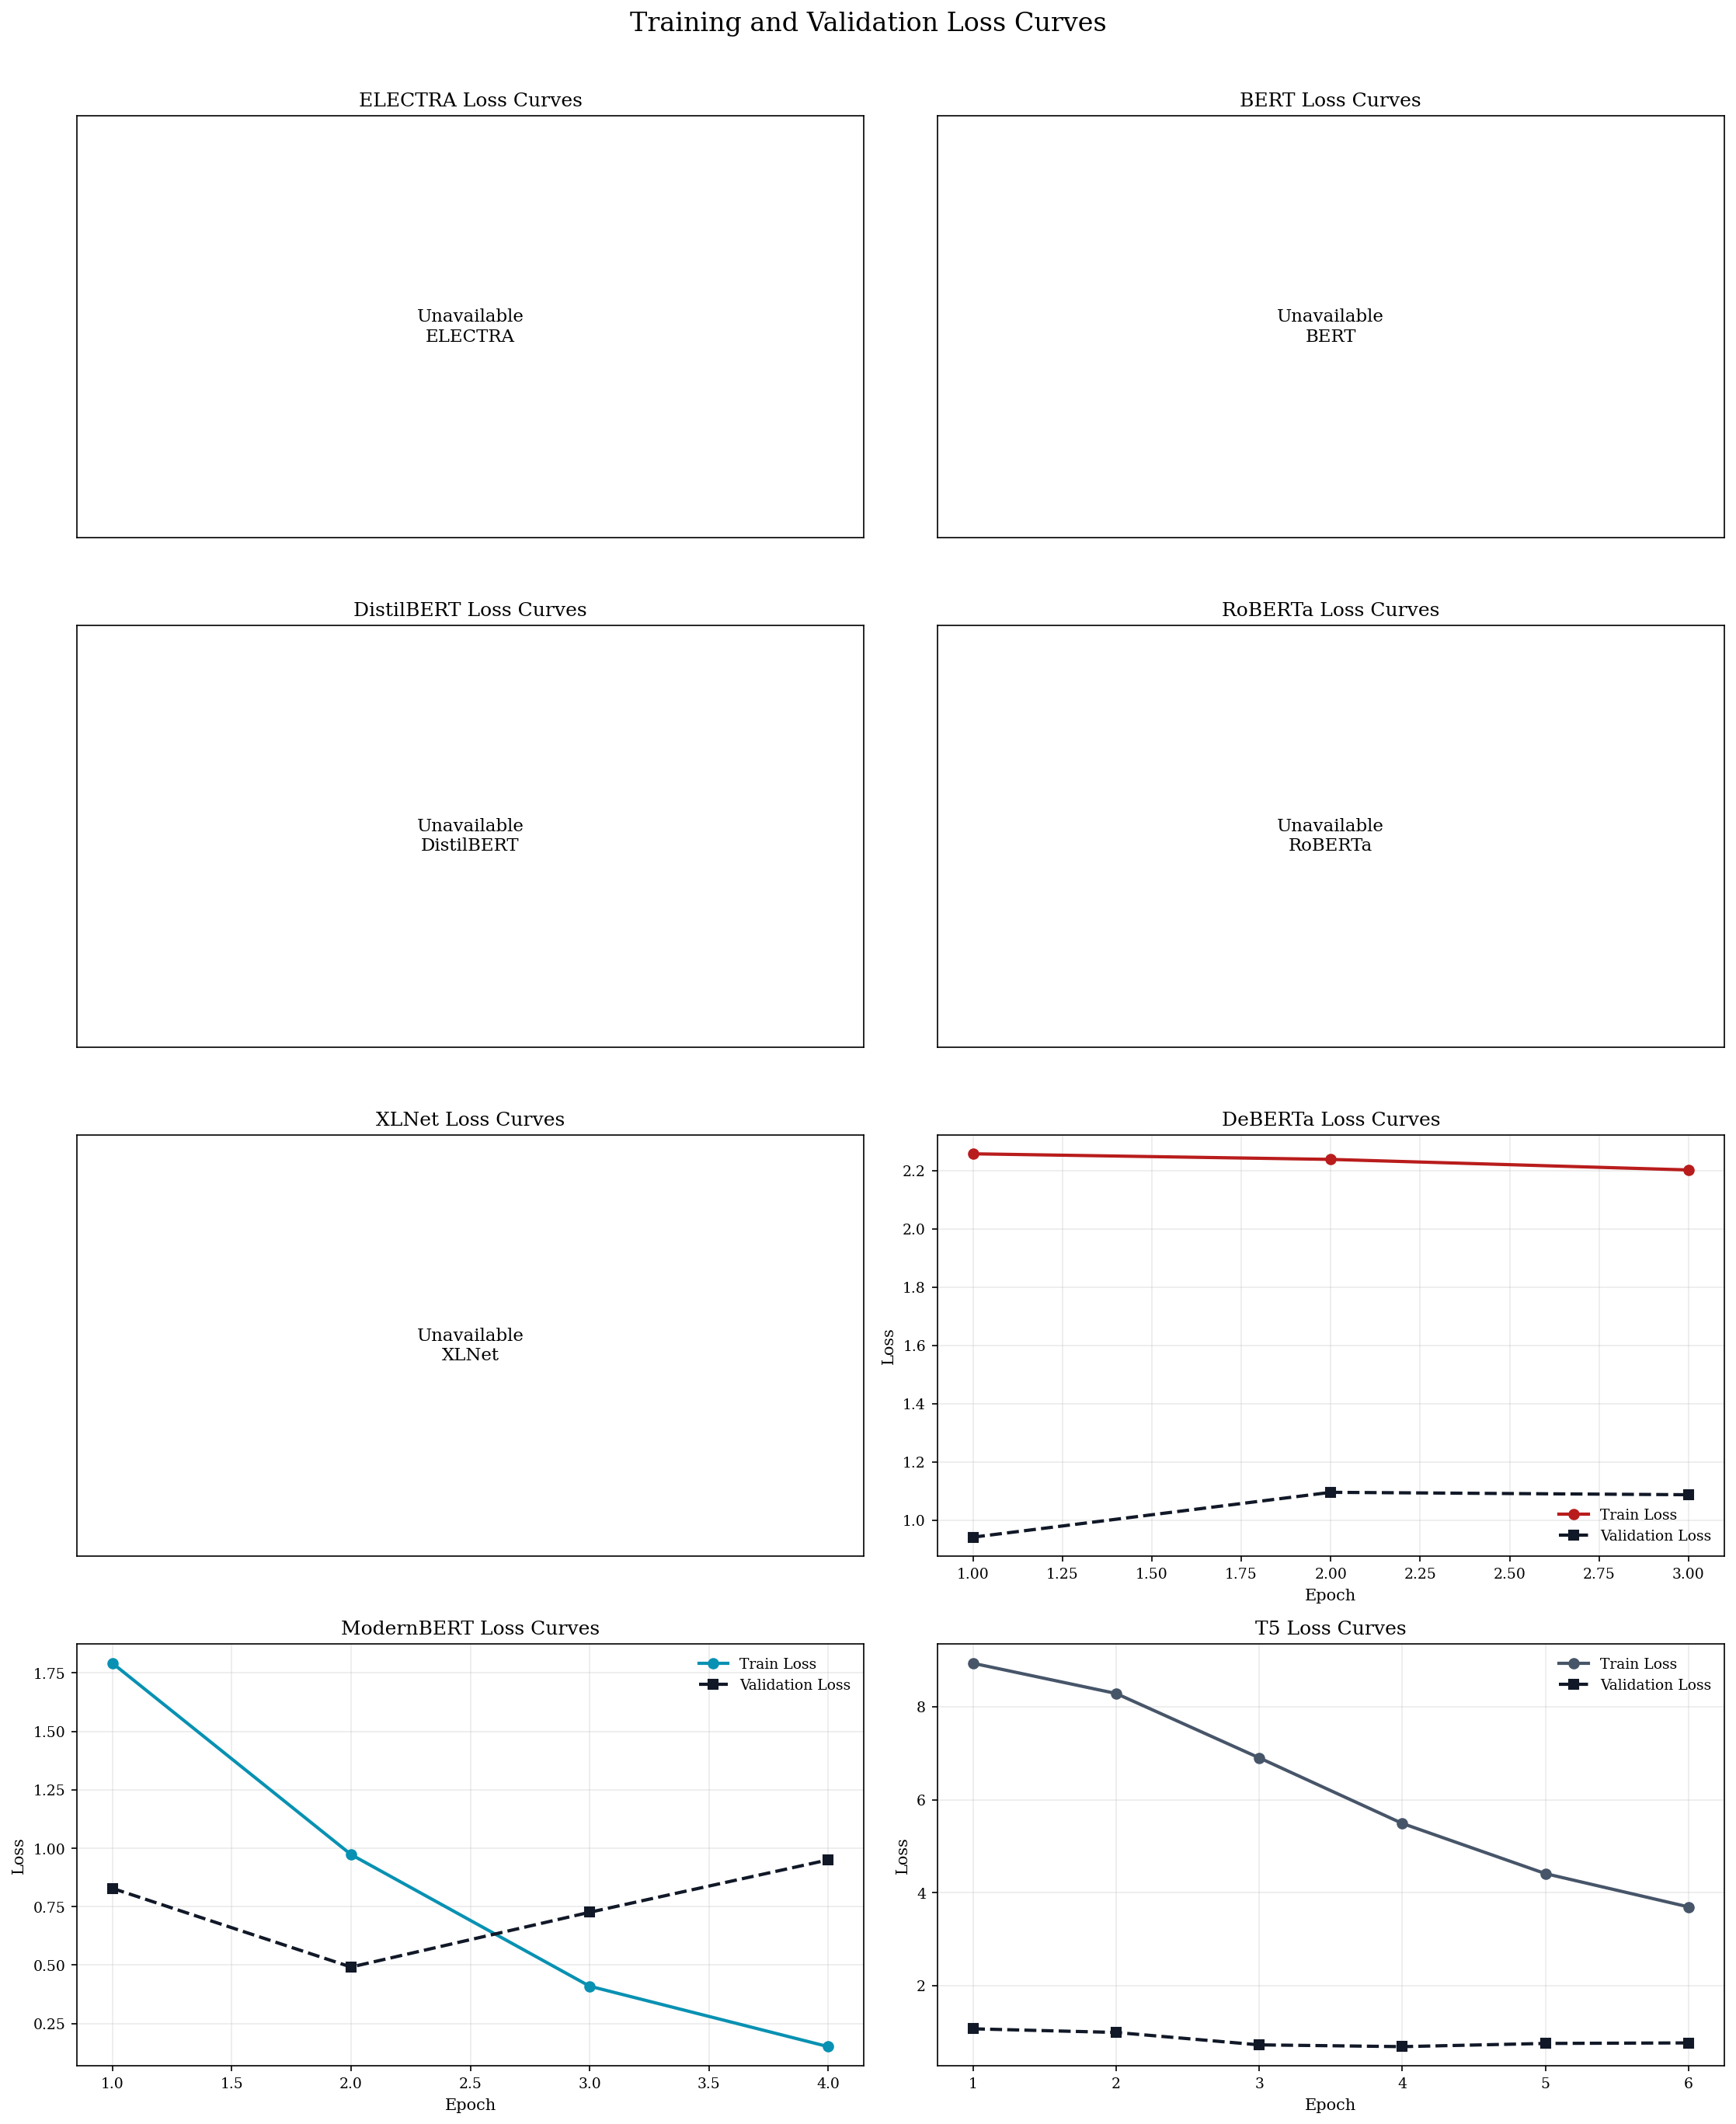

Missing loss curves:
- ELECTRA: No training history found for ELECTRA. Re-run training to generate paper-ready curves.
- BERT: No training history found for BERT. Re-run training to generate paper-ready curves.
- DistilBERT: No training history found for DistilBERT. Re-run training to generate paper-ready curves.
- RoBERTa: No training history found for RoBERTa. Re-run training to generate paper-ready curves.
- XLNet: No training history found for XLNet. Re-run training to generate paper-ready curves.


In [49]:
n_models = len(PAPER_MODEL_ORDER)
ncols = 2
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows), sharex=False)
axes = np.atleast_1d(axes).flatten()
missing = []

for ax, model_name in zip(axes, PAPER_MODEL_ORDER):
    try:
        train_curve, eval_curve = prepare_history_curves(model_name)
        if not train_curve.empty:
            ax.plot(train_curve["epoch"], train_curve["loss"], marker="o", linewidth=2, color=MODEL_COLORS[model_name], label="Train Loss")
        if not eval_curve.empty and "eval_loss" in eval_curve.columns:
            ax.plot(eval_curve["epoch"], eval_curve["eval_loss"], marker="s", linewidth=2, linestyle="--", color="#111827", label="Validation Loss")
        if train_curve.empty and (eval_curve.empty or "eval_loss" not in eval_curve.columns):
            raise ValueError("No loss history available")
        ax.set_title(f"{model_name} Loss Curves")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss")
        ax.grid(True, alpha=0.25)
        ax.legend(frameon=False, loc="best")
    except Exception as ex:
        missing.append(f"{model_name}: {ex}")
        ax.text(0.5, 0.5, f"Unavailable\n{model_name}", ha="center", va="center", fontsize=11)
        ax.set_title(f"{model_name} Loss Curves")
        ax.set_xticks([])
        ax.set_yticks([])

for ax in axes[len(PAPER_MODEL_ORDER):]:
    ax.axis("off")

fig.suptitle("Training and Validation Loss Curves", fontsize=16, y=1.01)
fig.tight_layout()
save_publication_figure(fig, "all_models_loss_curves")
plt.show()

if missing:
    print("Missing loss curves:")
    for item in missing:
        print(f"- {item}")


Saved: paper_figures/all_models_validation_weighted_f1.png
Saved: paper_figures/all_models_validation_weighted_f1.pdf


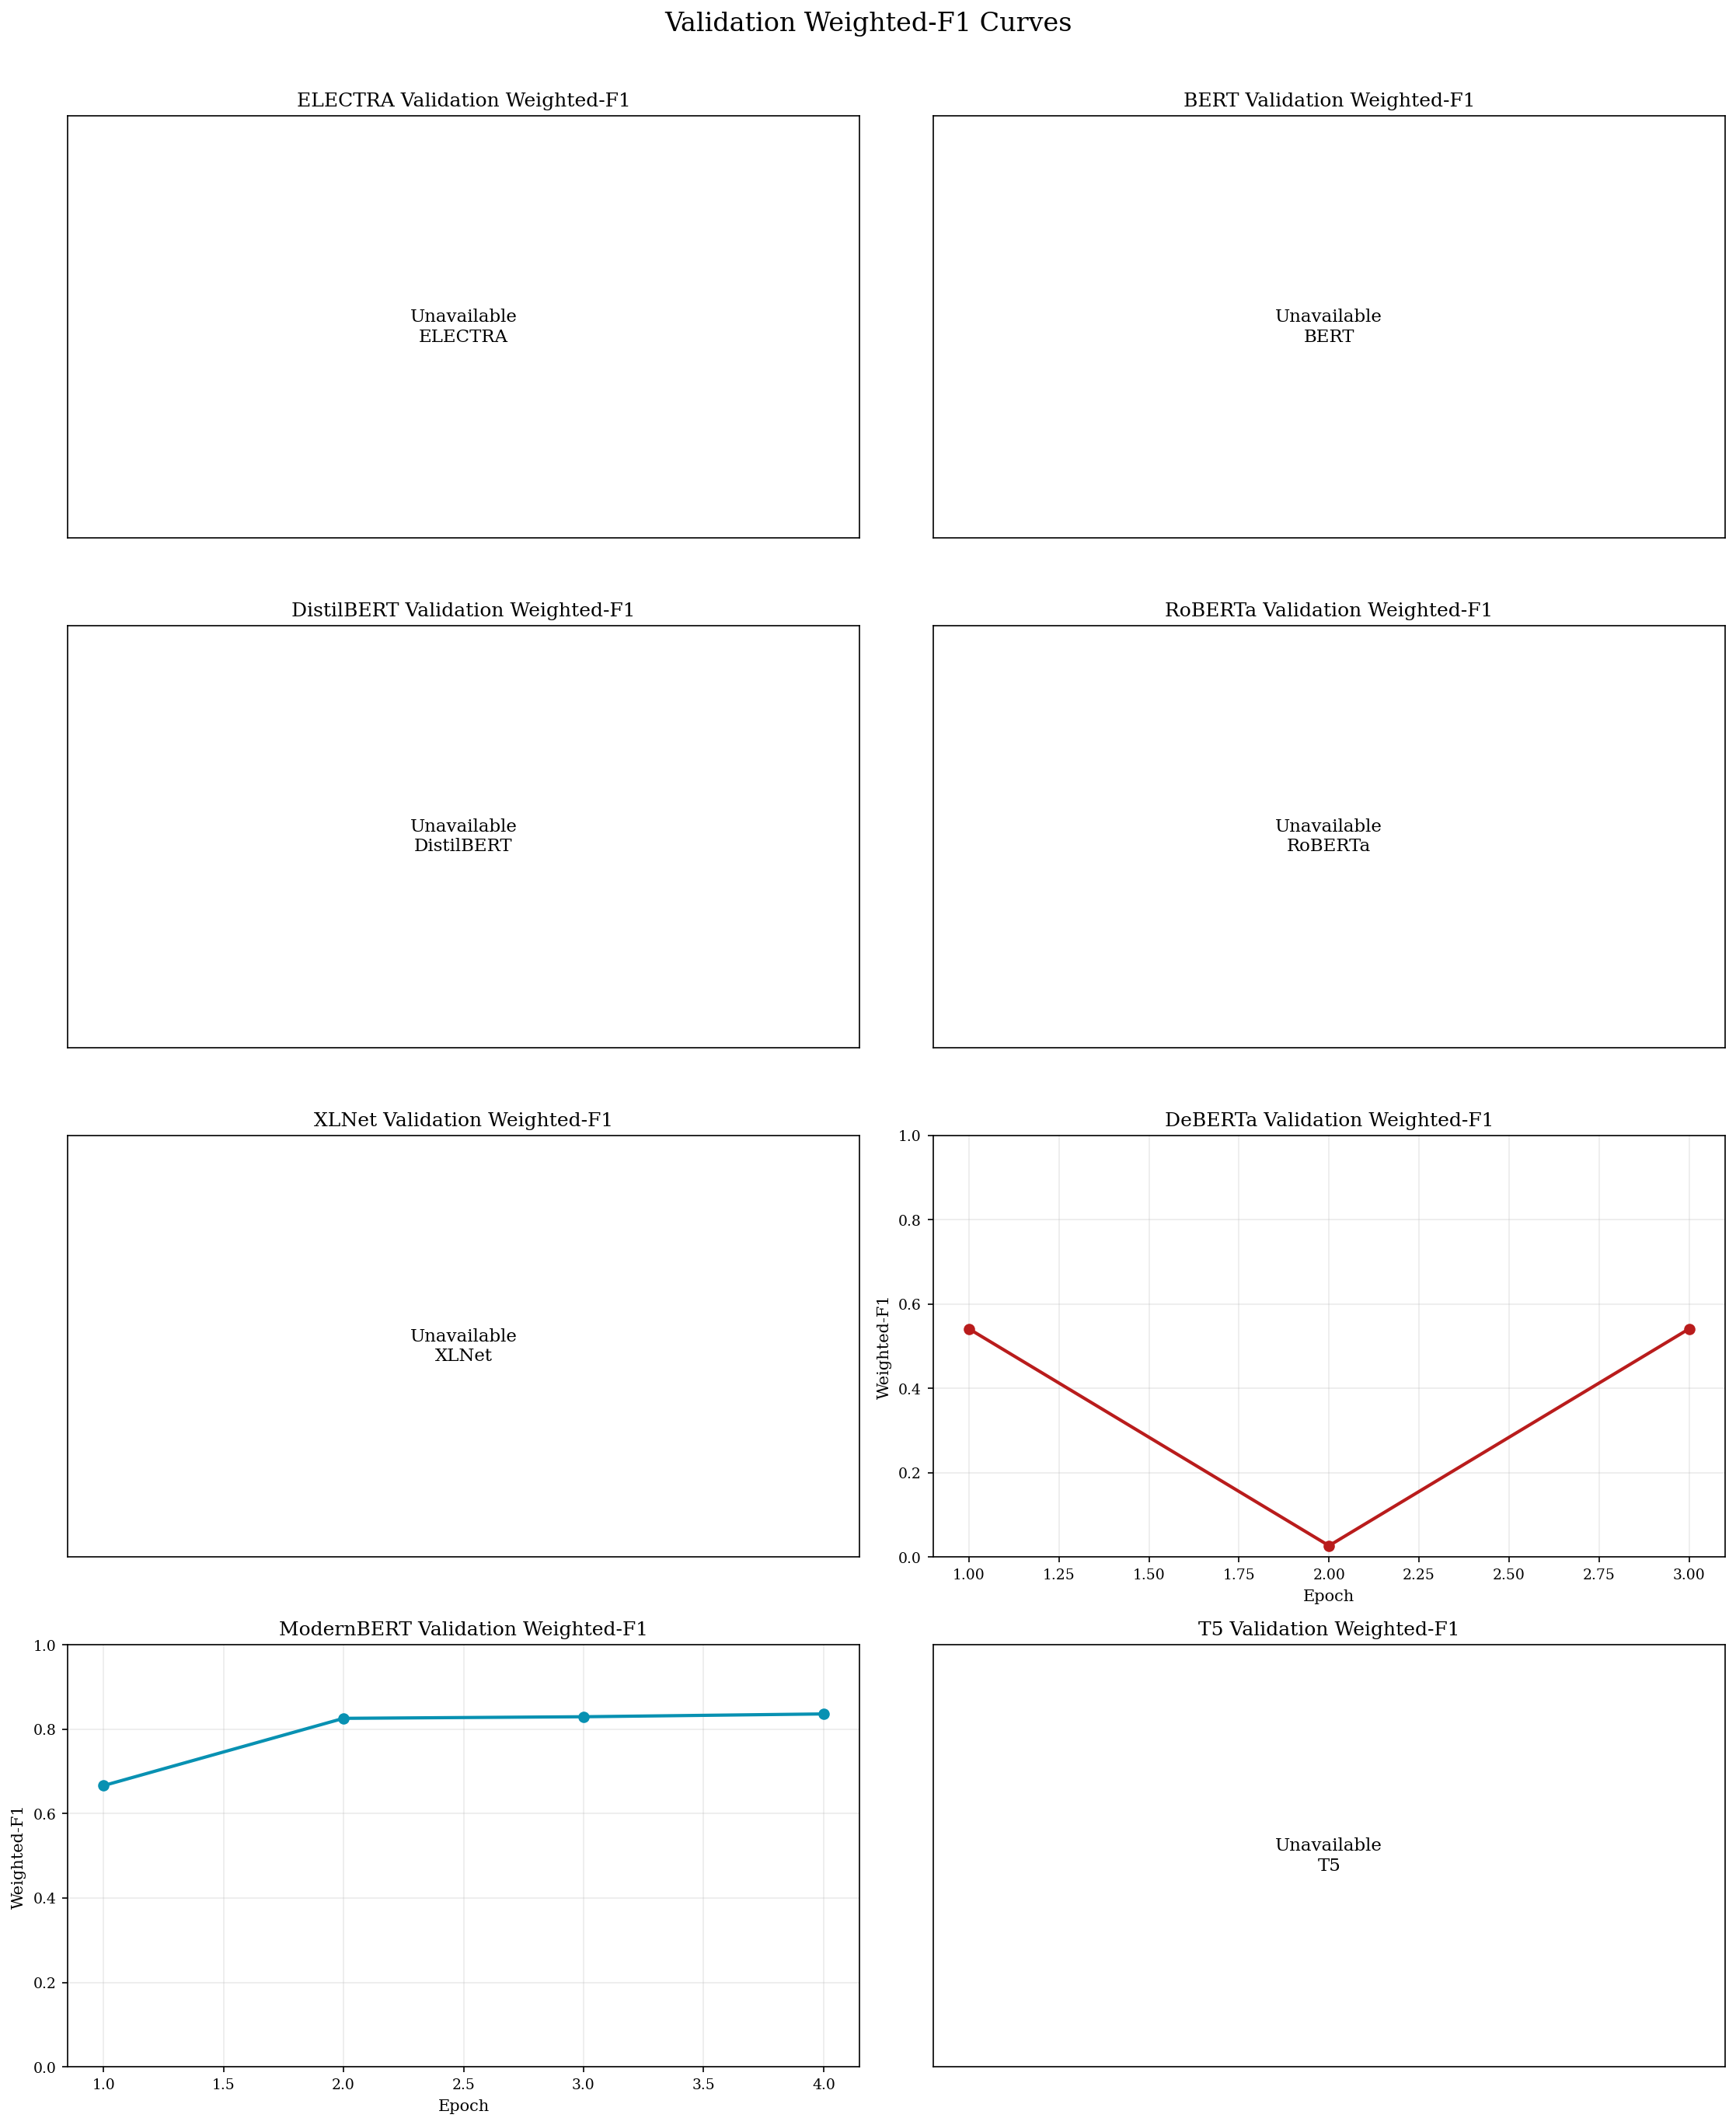

Missing validation weighted-F1 curves:
- ELECTRA: No training history found for ELECTRA. Re-run training to generate paper-ready curves.
- BERT: No training history found for BERT. Re-run training to generate paper-ready curves.
- DistilBERT: No training history found for DistilBERT. Re-run training to generate paper-ready curves.
- RoBERTa: No training history found for RoBERTa. Re-run training to generate paper-ready curves.
- XLNet: No training history found for XLNet. Re-run training to generate paper-ready curves.
- T5: Validation weighted-F1 history unavailable


In [50]:
n_models = len(PAPER_MODEL_ORDER)
ncols = 2
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4.5 * nrows), sharex=False)
axes = np.atleast_1d(axes).flatten()
missing = []

for ax, model_name in zip(axes, PAPER_MODEL_ORDER):
    try:
        _, eval_curve = prepare_history_curves(model_name)
        if eval_curve.empty or "eval_f1" not in eval_curve.columns:
            raise ValueError("Validation weighted-F1 history unavailable")
        ax.plot(eval_curve["epoch"], eval_curve["eval_f1"], marker="o", linewidth=2, color=MODEL_COLORS[model_name])
        ax.set_title(f"{model_name} Validation Weighted-F1")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Weighted-F1")
        ax.set_ylim(0, 1)
        ax.grid(True, alpha=0.25)
    except Exception as ex:
        missing.append(f"{model_name}: {ex}")
        ax.text(0.5, 0.5, f"Unavailable\n{model_name}", ha="center", va="center", fontsize=11)
        ax.set_title(f"{model_name} Validation Weighted-F1")
        ax.set_xticks([])
        ax.set_yticks([])

for ax in axes[len(PAPER_MODEL_ORDER):]:
    ax.axis("off")

fig.suptitle("Validation Weighted-F1 Curves", fontsize=16, y=1.01)
fig.tight_layout()
save_publication_figure(fig, "all_models_validation_weighted_f1")
plt.show()

if missing:
    print("Missing validation weighted-F1 curves:")
    for item in missing:
        print(f"- {item}")


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

,Model,Accuracy,F1,Precision,Recall,Source
0,DeBERTa,0.675676,0.544900,0.456538,0.675676,saved artifact: model_artifacts/deberta_augmented
1,ModernBERT,0.843844,0.837048,0.840191,0.843844,saved artifact: model_artifacts/modernbert_aug...
2,T5,0.660661,0.681527,0.771019,0.660661,in-memory trainer (single-GPU stability mode)


Saved: paper_figures/final_test_metric_comparison.png
Saved: paper_figures/final_test_metric_comparison.pdf


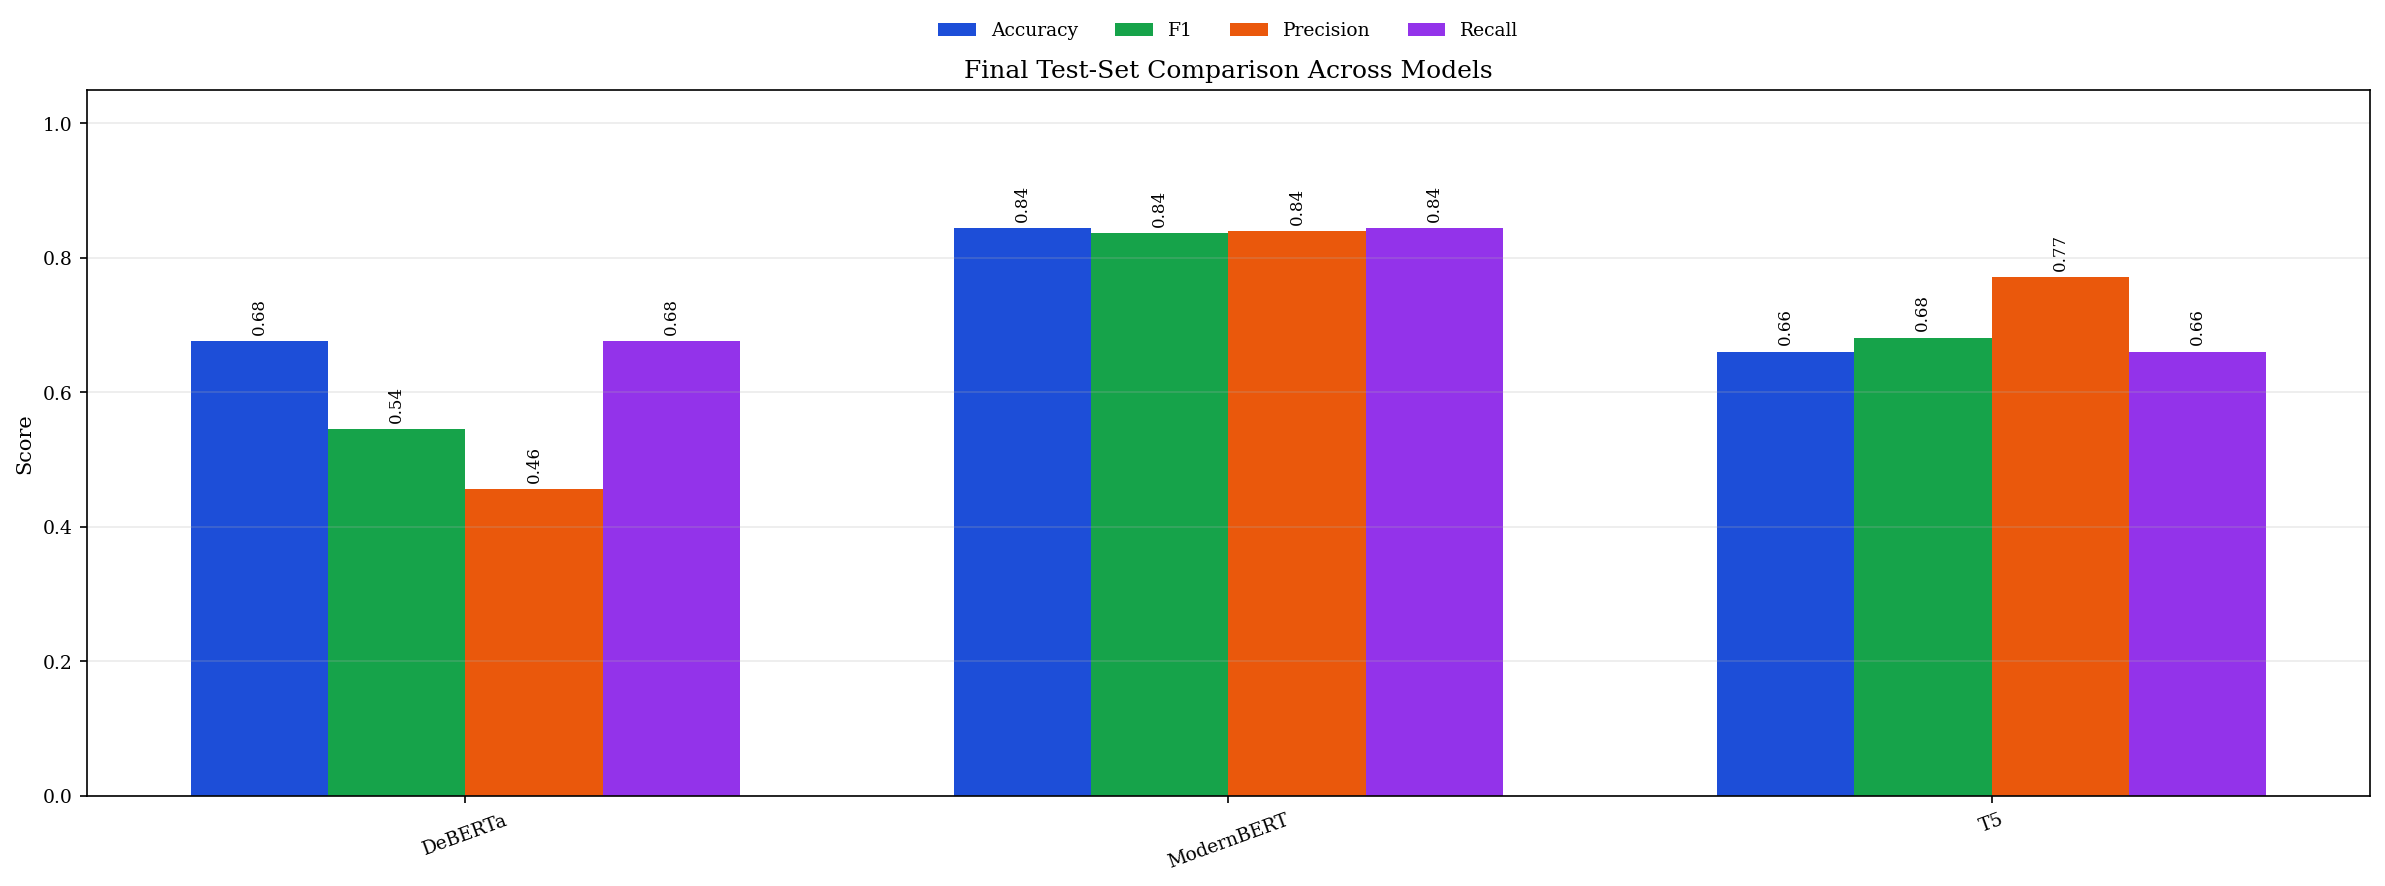

Models missing final test metrics:
- ELECTRA: No saved checkpoint found for ELECTRA in model_artifacts/electra_augmented
- BERT: No saved checkpoint found for BERT in model_artifacts/bert_augmented
- DistilBERT: No saved checkpoint found for DistilBERT in model_artifacts/distilbert_augmented
- RoBERTa: No saved checkpoint found for RoBERTa in model_artifacts/roberta_augmented
- XLNet: No saved checkpoint found for XLNet in model_artifacts/xlnet_augmented


In [51]:
metric_df, metric_missing = collect_test_metric_table()
display(metric_df)

if metric_df.empty:
    print("No model metrics are currently available. Train and save the models first.")
else:
    metric_plot_df = metric_df[["Model", "Accuracy", "F1", "Precision", "Recall"]].copy()
    melted = metric_plot_df.melt(id_vars="Model", var_name="Metric", value_name="Score")
    x = np.arange(len(metric_plot_df))
    width = 0.18
    metric_names = ["Accuracy", "F1", "Precision", "Recall"]

    fig, ax = plt.subplots(figsize=(16, 6))
    for idx, metric_name in enumerate(metric_names):
        scores = metric_plot_df[metric_name].to_numpy()
        offset = (idx - 1.5) * width
        bars = ax.bar(x + offset, scores, width=width, label=metric_name, color=METRIC_COLORS[metric_name])
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width() / 2, height + 0.01, f"{height:.2f}", ha="center", va="bottom", fontsize=8, rotation=90)

    ax.set_xticks(x)
    ax.set_xticklabels(metric_plot_df["Model"], rotation=20)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("Score")
    ax.set_title("Final Test-Set Comparison Across Models")
    ax.grid(axis="y", alpha=0.25)
    ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, 1.12))
    fig.tight_layout()
    save_publication_figure(fig, "final_test_metric_comparison")
    plt.show()

if metric_missing:
    print("Models missing final test metrics:")
    for item in metric_missing:
        print(f"- {item}")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

/tmp/ipykernel_23/3073550802.py:43: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Saved: paper_figures/all_models_confusion_matrices.png
Saved: paper_figures/all_models_confusion_matrices.pdf


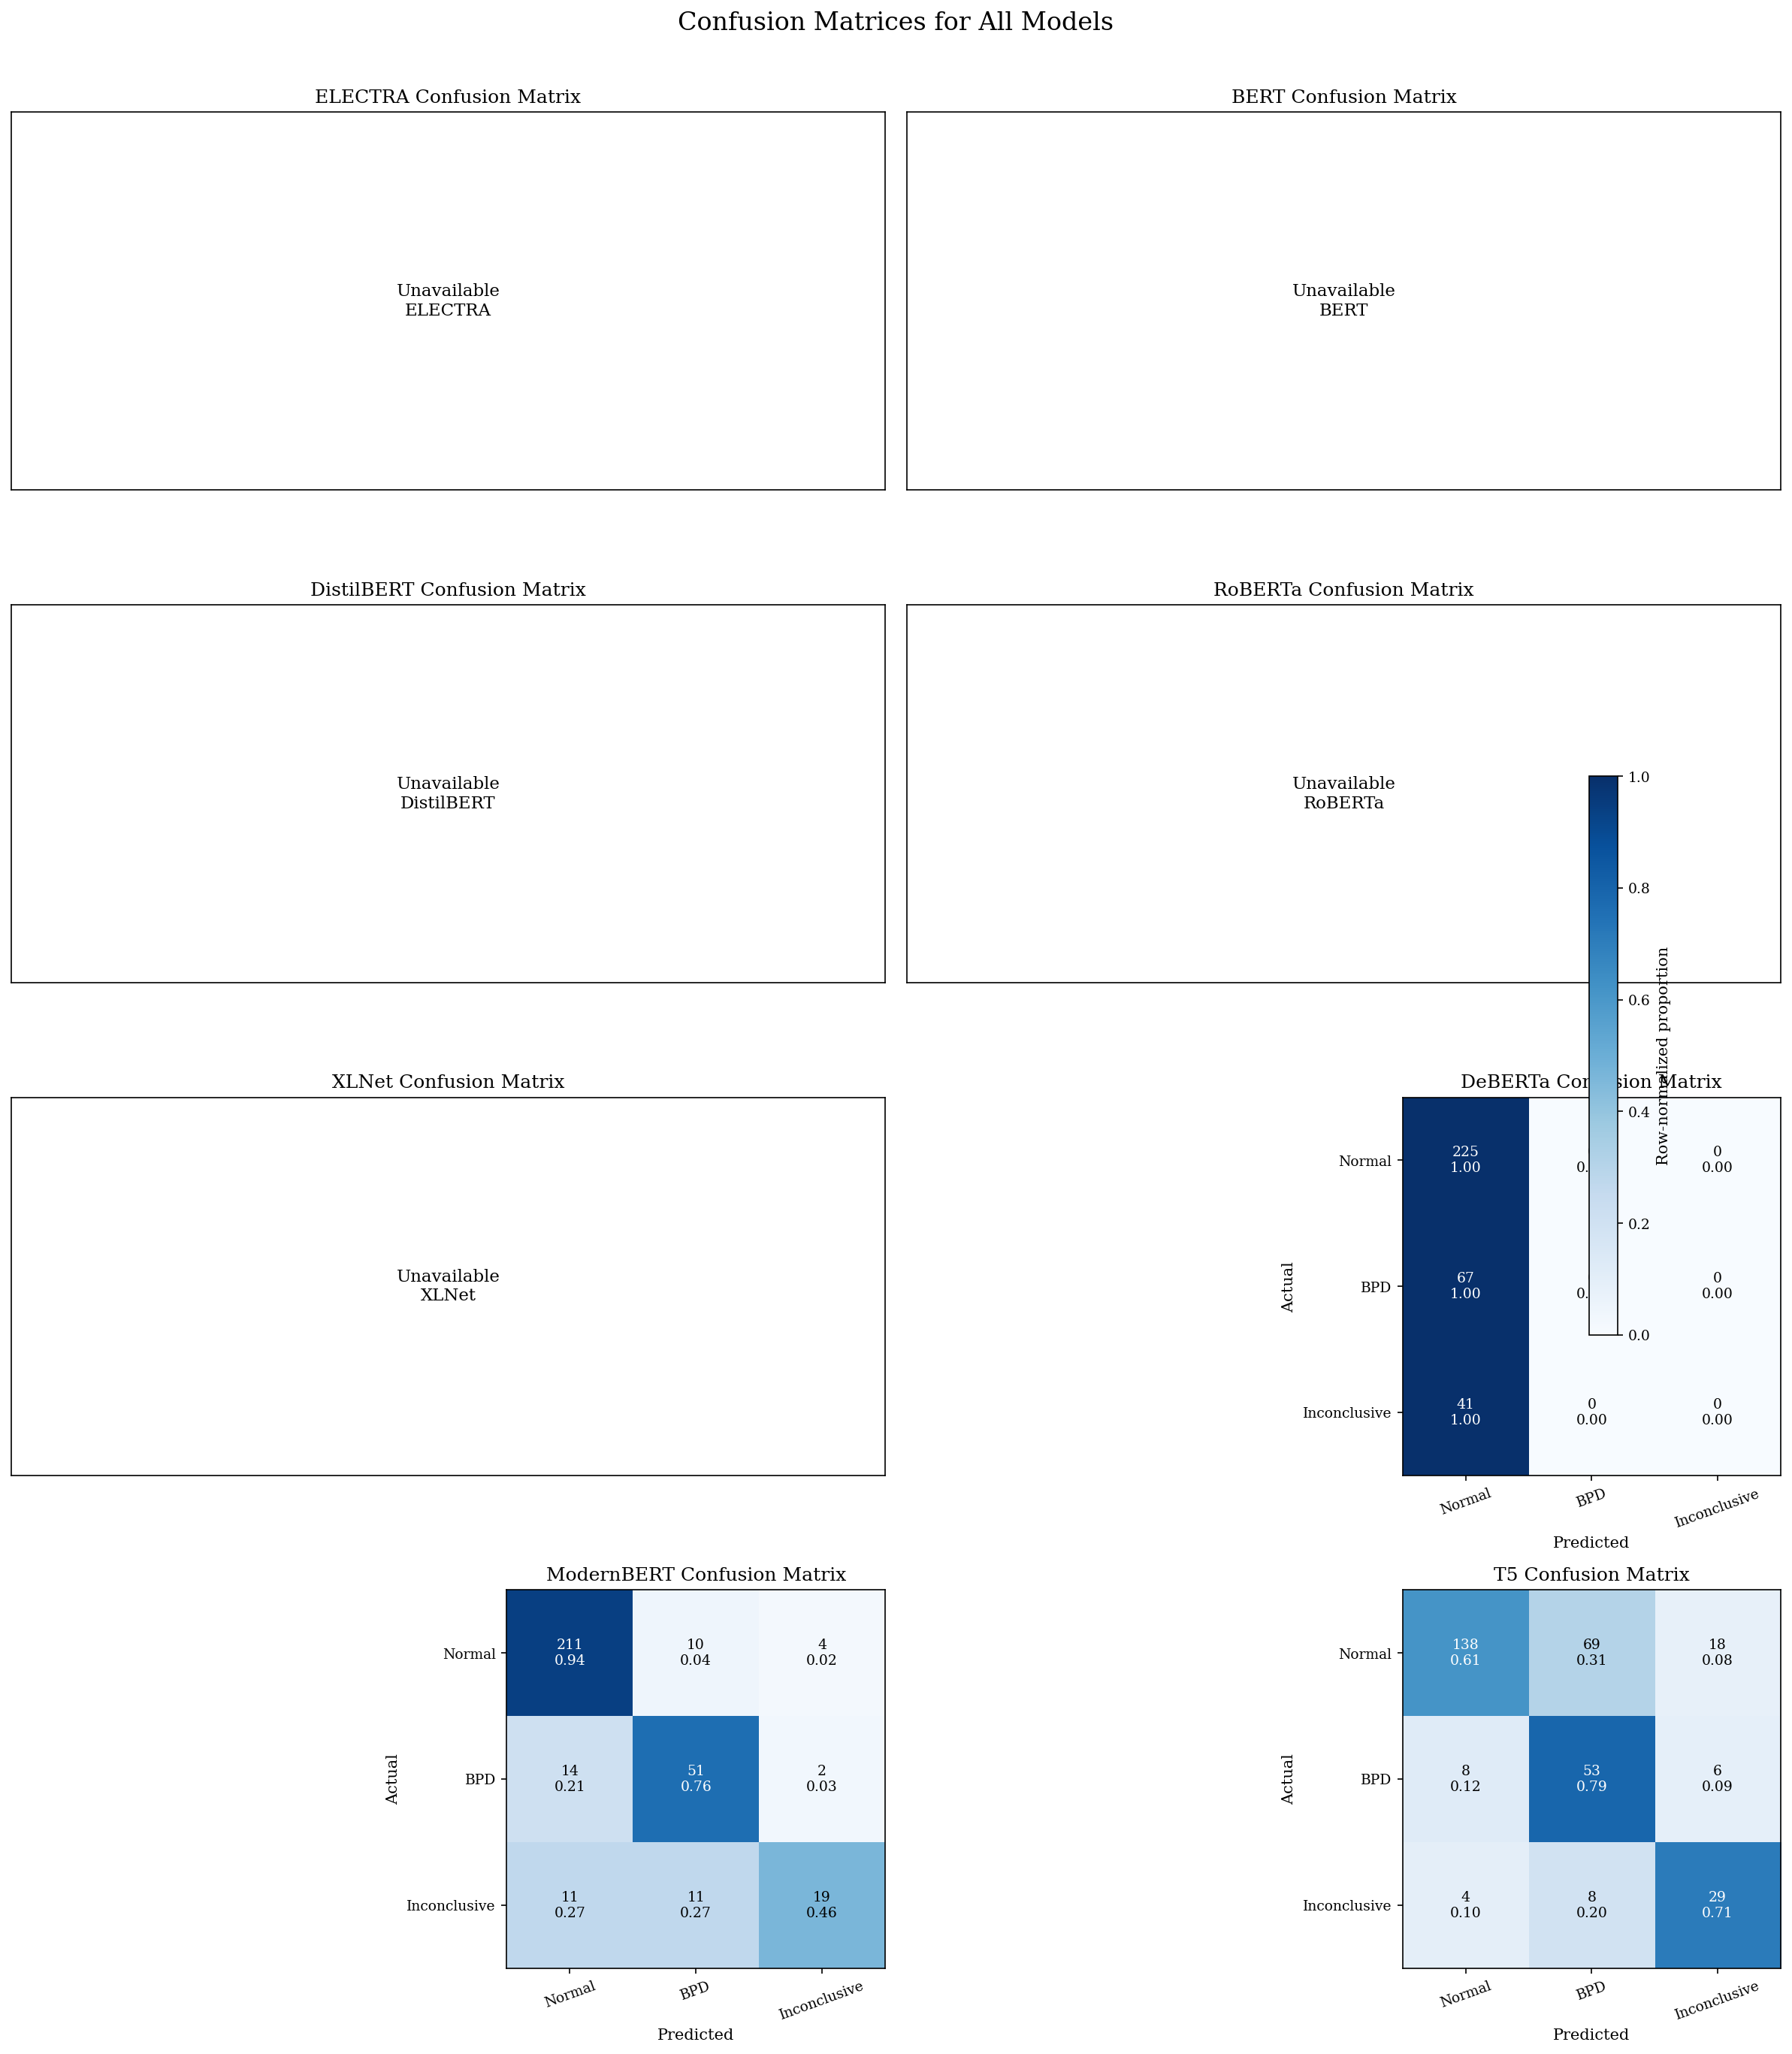

Models missing confusion matrices:
- ELECTRA: No saved checkpoint found for ELECTRA in model_artifacts/electra_augmented
- BERT: No saved checkpoint found for BERT in model_artifacts/bert_augmented
- DistilBERT: No saved checkpoint found for DistilBERT in model_artifacts/distilbert_augmented
- RoBERTa: No saved checkpoint found for RoBERTa in model_artifacts/roberta_augmented
- XLNet: No saved checkpoint found for XLNet in model_artifacts/xlnet_augmented


In [52]:
conf_tables, conf_missing = collect_confusion_tables()

n_models = len(PAPER_MODEL_ORDER)
ncols = 2
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.5 * nrows))
axes = np.atleast_1d(axes).flatten()
im = None

for ax, model_name in zip(axes, PAPER_MODEL_ORDER):
    if model_name not in conf_tables:
        ax.text(0.5, 0.5, f"Unavailable\n{model_name}", ha="center", va="center", fontsize=11)
        ax.set_title(f"{model_name} Confusion Matrix")
        ax.set_xticks([])
        ax.set_yticks([])
        continue

    cm = conf_tables[model_name]
    row_sums = cm.sum(axis=1, keepdims=True)
    cm_norm = np.divide(cm, row_sums, out=np.zeros_like(cm, dtype=float), where=row_sums != 0)

    im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{model_name} Confusion Matrix")
    ax.set_xticks(range(len(CLASS_NAMES)))
    ax.set_yticks(range(len(CLASS_NAMES)))
    ax.set_xticklabels(CLASS_NAMES, rotation=20)
    ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

    for row_idx in range(cm.shape[0]):
        for col_idx in range(cm.shape[1]):
            text_color = "white" if cm_norm[row_idx, col_idx] > 0.5 else "black"
            ax.text(col_idx, row_idx, f"{cm[row_idx, col_idx]}\n{cm_norm[row_idx, col_idx]:.2f}", ha="center", va="center", color=text_color, fontsize=9)

for ax in axes[len(PAPER_MODEL_ORDER):]:
    ax.axis("off")

if im is not None:
    cbar = fig.colorbar(im, ax=axes[:len(PAPER_MODEL_ORDER)].tolist(), fraction=0.02, pad=0.02)
    cbar.set_label("Row-normalized proportion")
fig.suptitle("Confusion Matrices for All Models", fontsize=16, y=1.01)
fig.tight_layout()
save_publication_figure(fig, "all_models_confusion_matrices")
plt.show()

if conf_missing:
    print("Models missing confusion matrices:")
    for item in conf_missing:
        print(f"- {item}")


# Paper Tables and Accuracy Figure

These cells prepare paper-ready summary tables and a simplified ranked accuracy figure for direct inclusion in the thesis/manuscript.


In [53]:
from pathlib import Path

def resolve_paper_export_dir():
    candidates = [
        Path('Thesis_Paper_editing_version_literature_review/generated'),
        Path('../Thesis_Paper_editing_version_literature_review/generated'),
    ]
    for candidate in candidates:
        if candidate.parent.exists():
            candidate.mkdir(parents=True, exist_ok=True)
            return candidate
    fallback = candidates[0]
    fallback.mkdir(parents=True, exist_ok=True)
    return fallback

PAPER_EXPORT_DIR = resolve_paper_export_dir()
BS = chr(92)

def latex_escape(value):
    return str(value).replace('_', BS + '_')

def latex_row(values):
    return ' & '.join(str(v) for v in values) + f' {BS}{BS}'

dataset_summary_df = pd.DataFrame([
    {'Item': 'Participants', 'Value': '362'},
    {'Item': 'Open-ended questions', 'Value': '9'},
    {'Item': 'Original QA pairs', 'Value': '3,258'},
    {'Item': 'Training samples (augmented)', 'Value': '5,238'},
    {'Item': 'Validation samples', 'Value': '333'},
    {'Item': 'Test samples', 'Value': '333'},
    {'Item': 'Classes', 'Value': '3 (Normal, BPD, Inconclusive)'},
])

paper_metric_df, metric_missing = collect_test_metric_table()
if paper_metric_df.empty:
    raise ValueError('No model metrics are available. Re-run the saved-checkpoint evaluation cells first.')

ranked_metric_df = paper_metric_df[['Model', 'Accuracy', 'F1', 'Precision', 'Recall']].copy()
ranked_metric_df = ranked_metric_df.sort_values(
    by=['F1', 'Accuracy', 'Precision', 'Recall'],
    ascending=[False, False, False, False]
).reset_index(drop=True)
ranked_metric_df.insert(0, 'Rank', np.arange(1, len(ranked_metric_df) + 1))

conf_tables, conf_missing = collect_confusion_tables()
top_models = ranked_metric_df['Model'].head(3).tolist()
classwise_rows = []
for model_name in top_models:
    cm = conf_tables[model_name]
    row_sums = cm.sum(axis=1)
    recalls = np.divide(np.diag(cm), row_sums, out=np.zeros(3, dtype=float), where=row_sums != 0)
    classwise_rows.append({
        'Model': model_name,
        'Normal': recalls[0],
        'BPD': recalls[1],
        'Inconclusive': recalls[2],
    })
classwise_recall_df = pd.DataFrame(classwise_rows)

display(dataset_summary_df)
display(ranked_metric_df)
display(classwise_recall_df)

dataset_summary_df.to_csv(PAPER_EXPORT_DIR / 'dataset_summary_table.csv', index=False)
ranked_metric_df.to_csv(PAPER_EXPORT_DIR / 'model_test_metrics.csv', index=False)
classwise_recall_df.to_csv(PAPER_EXPORT_DIR / 'classwise_recall_top_models.csv', index=False)

latex_lines = [
    '% Generated from experiments/bpd-project (2).ipynb',
    '',
    f'{BS}begin{{table}}[t]',
    f'{BS}centering',
    f'{BS}caption{{Summary of the augmented dataset used for transformer evaluation.}}',
    f'{BS}label{{tab:dataset_summary}}',
    f'{BS}begin{{tabular}}{{ll}}',
    f'{BS}hline',
    latex_row(['Item', 'Value']),
    f'{BS}hline',
]
for row in dataset_summary_df.to_dict('records'):
    latex_lines.append(latex_row([latex_escape(row['Item']), latex_escape(row['Value'])]))
latex_lines.extend([
    f'{BS}hline',
    f'{BS}end{{tabular}}',
    f'{BS}end{{table}}',
    '',
    f'{BS}begin{{table}}[t]',
    f'{BS}centering',
    f'{BS}small',
    f'{BS}caption{{Final augmented test-set performance ranked by weighted F1-score.}}',
    f'{BS}label{{tab:model_test_metrics}}',
    f'{BS}begin{{tabular}}{{lcccc}}',
    f'{BS}hline',
    latex_row(['Model', 'Accuracy', 'F1', 'Precision', 'Recall']),
    f'{BS}hline',
])
for row in ranked_metric_df.to_dict('records'):
    latex_lines.append(latex_row([
        row['Model'],
        f"{row['Accuracy']:.3f}",
        f"{row['F1']:.3f}",
        f"{row['Precision']:.3f}",
        f"{row['Recall']:.3f}",
    ]))
latex_lines.extend([
    f'{BS}hline',
    f'{BS}end{{tabular}}',
    f'{BS}end{{table}}',
    '',
    f'{BS}begin{{table}}[t]',
    f'{BS}centering',
    f'{BS}caption{{Class-wise recall for the three strongest models on the augmented test set.}}',
    f'{BS}label{{tab:classwise_recall}}',
    f'{BS}begin{{tabular}}{{lccc}}',
    f'{BS}hline',
    latex_row(['Model', 'Normal', 'BPD', 'Inconclusive']),
    f'{BS}hline',
])
for row in classwise_recall_df.to_dict('records'):
    latex_lines.append(latex_row([
        row['Model'],
        f"{row['Normal']:.2f}",
        f"{row['BPD']:.2f}",
        f"{row['Inconclusive']:.2f}",
    ]))
latex_lines.extend([
    f'{BS}hline',
    f'{BS}end{{tabular}}',
    f'{BS}end{{table}}',
    '',
    f'{BS}begin{{figure}}[t]',
    f'{BS}centering',
    f'{BS}includegraphics[width=0.9{BS}linewidth]{{generated/test_accuracy_comparison.pdf}}',
    f'{BS}caption{{Accuracy comparison across all evaluated transformer models on the augmented test set. ELECTRA achieved the highest test accuracy.}}',
    f'{BS}label{{fig:test_accuracy_comparison}}',
    f'{BS}end{{figure}}',
])

(PAPER_EXPORT_DIR / 'paper_results_snippets.tex').write_text('\n'.join(latex_lines) + '\n')

print(f'Paper tables exported to: {PAPER_EXPORT_DIR}')
if metric_missing:
    print('Models missing final test metrics:')
    for item in metric_missing:
        print(f'- {item}')
if conf_missing:
    print('Models missing confusion tables:')
    for item in conf_missing:
        print(f'- {item}')


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/138 [00:00<?, ?it/s]

,Item,Value
0,Participants,362
1,Open-ended questions,9
2,Original QA pairs,"3,258"
3,Training samples (augmented),"5,238"
4,Validation samples,333
5,Test samples,333
6,Classes,"3 (Normal, BPD, Inconclusive)"


,Rank,Model,Accuracy,F1,Precision,Recall
0,1,ModernBERT,0.843844,0.837048,0.840191,0.843844
1,2,T5,0.660661,0.681527,0.771019,0.660661
2,3,DeBERTa,0.675676,0.544900,0.456538,0.675676


,Model,Normal,BPD,Inconclusive
0,ModernBERT,0.937778,0.761194,0.463415
1,T5,0.613333,0.791045,0.707317
2,DeBERTa,1.000000,0.000000,0.000000


Paper tables exported to: Thesis_Paper_editing_version_literature_review/generated
Models missing final test metrics:
- ELECTRA: No saved checkpoint found for ELECTRA in model_artifacts/electra_augmented
- BERT: No saved checkpoint found for BERT in model_artifacts/bert_augmented
- DistilBERT: No saved checkpoint found for DistilBERT in model_artifacts/distilbert_augmented
- RoBERTa: No saved checkpoint found for RoBERTa in model_artifacts/roberta_augmented
- XLNet: No saved checkpoint found for XLNet in model_artifacts/xlnet_augmented
Models missing confusion tables:
- ELECTRA: No saved checkpoint found for ELECTRA in model_artifacts/electra_augmented
- BERT: No saved checkpoint found for BERT in model_artifacts/bert_augmented
- DistilBERT: No saved checkpoint found for DistilBERT in model_artifacts/distilbert_augmented
- RoBERTa: No saved checkpoint found for RoBERTa in model_artifacts/roberta_augmented
- XLNet: No saved checkpoint found for XLNet in model_artifacts/xlnet_augmented


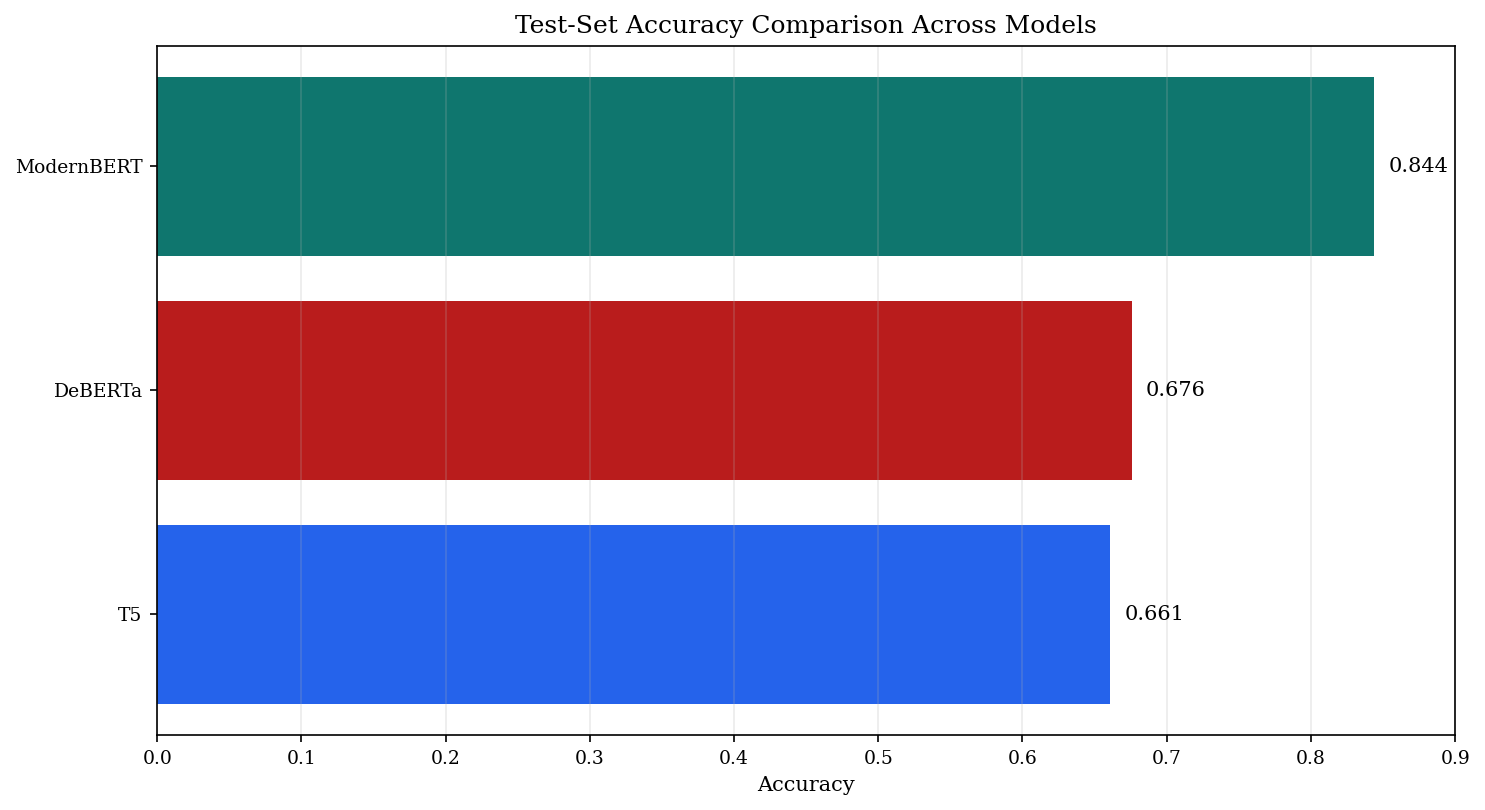

Saved: Thesis_Paper_editing_version_literature_review/generated/test_accuracy_comparison.png
Saved: Thesis_Paper_editing_version_literature_review/generated/test_accuracy_comparison.pdf


In [54]:
accuracy_plot_df = ranked_metric_df.sort_values('Accuracy', ascending=True).copy()

fig, ax = plt.subplots(figsize=(10, 5.5))
colors = []
for _, row in accuracy_plot_df.iterrows():
    if row['Rank'] == 1:
        colors.append('#0f766e')
    elif row['Model'] == 'DeBERTa':
        colors.append('#b91c1c')
    else:
        colors.append('#2563eb')

bars = ax.barh(accuracy_plot_df['Model'], accuracy_plot_df['Accuracy'], color=colors)
ax.set_xlim(0, 0.90)
ax.set_xlabel('Accuracy')
ax.set_title('Test-Set Accuracy Comparison Across Models')
ax.grid(axis='x', alpha=0.25)

for bar, score in zip(bars, accuracy_plot_df['Accuracy']):
    ax.text(score + 0.01, bar.get_y() + bar.get_height() / 2, f'{score:.3f}', va='center')

fig.tight_layout()
fig.savefig(PAPER_EXPORT_DIR / 'test_accuracy_comparison.png', bbox_inches='tight', dpi=400)
fig.savefig(PAPER_EXPORT_DIR / 'test_accuracy_comparison.pdf', bbox_inches='tight')
plt.show()
print(f"Saved: {PAPER_EXPORT_DIR / 'test_accuracy_comparison.png'}")
print(f"Saved: {PAPER_EXPORT_DIR / 'test_accuracy_comparison.pdf'}")
